# 4. Exploratory analysis: SST, currents and fish catch (RQ1)

**What it does**
- Builds its own regional extract (89°W–65°W, 49°S–4°S, with velocity): about 2.6 million readings from 695 drifters.
- Computes location-corrected monthly SST anomalies and checks them against ONI and Niño 1+2. This is why the project uses the coastal index (Niño 1+2 / ICEN) rather than ONI.
- Measures the current (velocity) response to El Niño and La Niña, using drogued drifters only.
- Runs first baseline forecasts once a coastal event is flagged.
- Compares yearly fish catch (Sea Around Us, 1982–2019) with coastal events and the drifter SST, and tests whether SST improves anchoveta catch forecasts.

**Inputs**
- `data/cache/humboldt_obs.npz` (built from the `gdp1h` arrays on the first run), `data/cache/drogue_lost_date.npy`
- `data/raw/oni.ascii.txt`, `data/raw/sstoi.indices`, `data/raw/fish_data/fish_data.xlsx`

**Outputs**
- Figures in `figures/`: `sst_vs_oni.png`, `sst_north_vs_oni.png`, `sst_vs_nino12.png`, `fig3_forecast_skill.png`, `fish_catch_coastal_enso.png`, `fish_vs_drifter_sst.png`, `anchoveta_*.png`

Run this notebook from the `notebooks/` folder, top to bottom. It is independent of notebooks 1–3: cells 1–9 come first, then the current cells (10–14) and the fish cells in order, because each fish cell uses results from the one before.

In [1]:
# Download all libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.gridspec import GridSpec

# Drifter cache: not in git; missing gdp1h arrays are downloaded here on the first run
CACHE = Path("../data/cache")
EXTRACT = CACHE / "humboldt_obs.npz"

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)

VARS = ["lon", "lat", "time", "ve", "vn", "sst"]

def download_gdp1h(variables):
    """Download any missing Clouddrift gdp1h arrays into data/cache, one variable at a time."""
    missing = [v for v in variables if not (CACHE / f"{v}.npy").exists()]
    if not missing:
        return
    from clouddrift.datasets import gdp1h
    CACHE.mkdir(parents=True, exist_ok=True)
    ds = gdp1h()
    for v in missing:
        print(f"Downloading gdp1h {v} ...")
        np.save(CACHE / f"{v}.npy", ds[v].values)


# The extract needs all the arrays; the drogue cell later also needs id.npy
download_gdp1h(["id"] if EXTRACT.exists() else VARS + ["rowsize", "id"])

# Selected region: Humboldt Region. Study time: 2001 to 2022
R = dict(lon=(-89, -65), lat=(-49, -4))
START, END = np.datetime64("2001-01-01", "ns"), np.datetime64("2023-01-01", "ns")


def build_extract(chunk=2_000_000):
    """Keep valid SST and velocity observations in the study region and period.

    The global arrays need more memory than this laptop has, so they are read from disk
    in chunks. This runs once; later runs load the small extract file.
    """
    raw = {v: np.load(CACHE / f"{v}.npy", mmap_mode="r") for v in VARS}
    ids = np.load(CACHE / "id.npy")
    last_row = np.cumsum(np.load(CACHE / "rowsize.npy"))
    parts = {k: [] for k in ["id", "time", "lon", "lat", "sst", "ve", "vn"]}
    for a in range(0, len(raw["lon"]), chunk):
        b = a + chunk
        lon, lat = np.asarray(raw["lon"][a:b]), np.asarray(raw["lat"][a:b])
        rows = np.flatnonzero((lon >= R["lon"][0]) & (lon <= R["lon"][1])
                              & (lat >= R["lat"][0]) & (lat <= R["lat"][1]))
        if len(rows) == 0:
            continue
        t = np.asarray(raw["time"][a:b])[rows]
        sst, ve, vn = (np.asarray(raw[v][a:b])[rows] for v in ["sst", "ve", "vn"])
        good = (t >= START) & (t < END) & np.isfinite(sst) & np.isfinite(ve) & np.isfinite(vn)
        rows = rows[good]
        parts["id"].append(ids[np.searchsorted(last_row, a + rows, side="right")])
        parts["time"].append(t[good])
        parts["lon"].append(lon[rows])
        parts["lat"].append(lat[rows])
        parts["sst"].append(sst[good])
        parts["ve"].append(ve[good])
        parts["vn"].append(vn[good])
    np.savez(EXTRACT, **{k: np.concatenate(v) for k, v in parts.items()})


if not EXTRACT.exists():
    build_extract()


In [2]:
print("Applying filters to local cache...")

# 1. Assemble the clean DataFrame from the regional extract
obs = np.load(EXTRACT)
df = pd.DataFrame({
    "id": obs["id"],
    "time": obs["time"],
    "lon": obs["lon"],
    "lat": obs["lat"],
    "sst_degC": obs["sst"] - 273.15,  # Convert SST from Kelvin to Celsius
    "ve": obs["ve"],
    "vn": obs["vn"],
})

# 2. Calculate the overall speed using sqrt(ve^2 + vn^2)
df["speed"] = np.hypot(df["ve"], df["vn"])

# 3. Add time groupings and apply the physical sanity check we discussed earlier
df["year"] = df["time"].dt.year
df["month"] = df["time"].dt.month
df["doy"] = df["time"].dt.dayofyear
# 5 C floor: real winter SST south of 40S falls below 10 C, but values outside this range are sensor errors
df = df[(df["sst_degC"] >= 5.0) & (df["sst_degC"] <= 35.0)]
# Remove readings east of the Andes: these are in the Atlantic, not the Humboldt system
df = df[~((df["lat"] < -40) & (df["lon"] > -71))].reset_index(drop=True)

print(f"\nSuccessfully loaded {len(df):,} valid observations.")
print(df.head())


Applying filters to local cache...



Successfully loaded 2,537,111 valid observations.
      id                time        lon        lat   sst_degC      ve      vn     speed  year  month  doy
0  29327 2003-10-07 14:00:00 -88.997658 -34.694439  14.248993  0.1575  0.2020  0.256145  2003     10  280
1  29327 2003-10-07 15:00:00 -88.991379 -34.688568  14.268005  0.1552  0.2016  0.254420  2003     10  280
2  29327 2003-10-07 16:00:00 -88.986092 -34.679878  14.287994  0.1345  0.2642  0.296466  2003     10  280
3  29327 2003-10-07 17:00:00 -88.980850 -34.671059  14.307007  0.1594  0.3087  0.347425  2003     10  280
4  29327 2003-10-07 18:00:00 -88.973770 -34.660419  14.329010  0.1637  0.3122  0.352515  2003     10  280


In [3]:
# ============================================================================
# LOCATION-CORRECTED MONTHLY SST ANOMALIES
# Place this directly after the cell that builds `df`.
# Needs numpy, pandas and scipy 1.8 or newer.
#
# THE PROBLEM
# Drifters are not spread evenly, and the south of the region is much colder
# than the north. A month with more southern drifters therefore looks cold even
# if the ocean has not changed. The simple monthly mean has a 0.92 correlation
# with the drifters' mean latitude, so it mostly tracks where they were.
#
# THE FIX
# Compare each reading with what is normal for that place and time of year,
# then average those differences (anomalies) instead of the raw temperatures.
#
# WHAT THIS CELL CREATES
# In df (one row per hourly reading):
#   sst_baseline    normal SST for that location and day of year (C)
#   sst_anom        sst_degC minus sst_baseline (C)
#
# In sst_monthly (one row per month, 2001 to 2022):
#   sst_anom        regional anomaly, the main corrected series (C)
#   sst_anom_north  anomaly north of 30S (C)
#   sst_anom_south  anomaly south of 30S (C)
#   sst_adjusted    regional normal for that calendar month plus sst_anom (C)
#   sst_simple      uncorrected monthly mean, kept for comparison (C)
#   mean_lat        mean latitude of that month's readings
#   n_drifters      number of drifters in the month
#   n_cells         number of 2-degree cells used in the month
#   low_coverage    True if under 10 cells or under 5 drifters; treat with care
#   date            15th of the month, for plotting
# ============================================================================
from scipy.interpolate import BSpline

# ---- Step 1: filters --------------------------------------------------------
# Real winter SST south of 40S falls below 10 C, so a 10 C minimum makes the far
# south look about 1.9 C too warm. If df was built with that minimum, start again
# from the clean arrays so those cold readings return.
if "clean_sst" in globals():
    df = pd.DataFrame({"id": clean_ids, "time": clean_time, "lon": clean_lon, "lat": clean_lat,
                       "sst_degC": clean_sst, "ve": clean_ve, "vn": clean_vn, "speed": clean_speed})
    df["year"] = df["time"].dt.year
    df["month"] = df["time"].dt.month

df["doy"] = df["time"].dt.dayofyear
df = df[(df["sst_degC"] >= 5.0) & (df["sst_degC"] <= 35.0)]
# The region's box also catches the Atlantic east of the Andes, which is not part of the Humboldt system
df = df[~((df["lat"] < -40) & (df["lon"] > -71))].reset_index(drop=True)

# ---- Step 2: the baseline model ---------------------------------------------
# SST(lat, lon, day of year) = smooth map + smooth maps of the annual and
# semi-annual cycles. A smooth fit is needed because many 1-degree cells, mainly
# in the north, have only a few drifters and do not cover every calendar month.
LAT_SPLINE = (-49, -4, 16)   # (min, max, number of basis functions)
LON_SPLINE = (-89, -65, 10)
SMOOTHING = 1.0              # larger values give a smoother map
N_HARMONICS = 2              # 1 = annual cycle, 2 = adds the semi-annual cycle


def spline_basis(x, lo, hi, n, degree=3):
    """Smooth curves along one axis, which combine to form the map."""
    inner = np.linspace(lo, hi, n - degree + 1)
    knots = np.r_[[lo] * degree, inner, [hi] * degree]
    return BSpline.design_matrix(np.clip(x, lo, hi - 1e-9), knots, degree).toarray()


def seasonal_terms(doy):
    """Constant term plus sine and cosine waves for each seasonal cycle."""
    w = 2 * np.pi * doy / 365.25
    terms = [np.ones_like(w)]
    for k in range(1, N_HARMONICS + 1):
        terms += [np.cos(k * w), np.sin(k * w)]
    return np.column_stack(terms)


def design_matrix(lat, lon, doy):
    """Combine latitude, longitude and season so each season gets its own map."""
    A, B, H = spline_basis(lat, *LAT_SPLINE), spline_basis(lon, *LON_SPLINE), seasonal_terms(doy)
    surface = (A[:, :, None] * B[:, None, :]).reshape(len(lat), -1)
    return (H[:, :, None] * surface[:, None, :]).reshape(len(lat), -1)


def roughness_penalty():
    """Penalise sharp changes between neighbouring map points."""
    D = lambda n: np.diff(np.eye(n), 2, axis=0)
    na, nb = LAT_SPLINE[2], LON_SPLINE[2]
    spatial = (np.kron(D(na).T @ D(na), np.eye(nb))
               + np.kron(np.eye(na), D(nb).T @ D(nb)))
    return np.kron(np.eye(1 + 2 * N_HARMONICS), spatial)


def predict(beta, lat, lon, doy, chunk=20_000):
    """Normal SST for any set of points, in chunks to keep memory use low."""
    out = np.empty(len(lat))
    for i in range(0, len(lat), chunk):
        s = slice(i, i + chunk)
        out[s] = design_matrix(lat[s], lon[s], doy[s]) @ beta
    return out


# ---- Step 3: fit the baseline -----------------------------------------------
# Fit to 1-degree cell monthly averages, so a drifter's many hourly readings do
# not dominate. Each year gets equal total weight, so data-rich years do not
# define what is normal.
units = (df.assign(cell_lat=np.floor(df["lat"]), cell_lon=np.floor(df["lon"]))
           .groupby(["cell_lat", "cell_lon", "year", "month"])
           .agg(lat=("lat", "mean"), lon=("lon", "mean"), doy=("doy", "mean"), sst=("sst_degC", "mean"))
           .reset_index())
unit_weight = (1 / units.groupby("year")["sst"].transform("size")).to_numpy()
unit_weight = unit_weight * len(units) / unit_weight.sum()

# Build the fit one year at a time, so the full matrix never sits in memory
XtWX_year, XtWy_year = {}, {}
for year in sorted(units["year"].unique()):
    k = (units["year"] == year).to_numpy()
    Xk = design_matrix(units["lat"].to_numpy()[k], units["lon"].to_numpy()[k], units["doy"].to_numpy()[k])
    XtWX_year[year] = (Xk.T * unit_weight[k]) @ Xk
    XtWy_year[year] = (Xk.T * unit_weight[k]) @ units["sst"].to_numpy()[k]
XtWX, XtWy = sum(XtWX_year.values()), sum(XtWy_year.values())
penalty = SMOOTHING * roughness_penalty() + 1e-6 * np.eye(XtWX.shape[0])

# Fit using all years; used only for the regional normal in Step 6
beta_full = np.linalg.solve(XtWX + penalty, XtWy)

# ---- Step 4: anomaly for each reading ---------------------------------------
# Each year is compared with a baseline fitted WITHOUT that year. Otherwise an
# unusual year would shift its own definition of normal and hide part of its signal.
df["sst_baseline"] = np.nan
for year, rows in df.groupby("year").indices.items():
    beta = np.linalg.solve(XtWX - XtWX_year[year] + penalty, XtWy - XtWy_year[year])
    df.iloc[rows, df.columns.get_loc("sst_baseline")] = predict(
        beta, df["lat"].to_numpy()[rows], df["lon"].to_numpy()[rows], df["doy"].to_numpy()[rows].astype(float))
df["sst_anom"] = df["sst_degC"] - df["sst_baseline"]

# ---- Step 5: combine anomalies into monthly series --------------------------
# Average within 2-degree cells first, so a cluster of drifters counts as one
# location. Then average the cells, weighted by area, as cells shrink further south.
CELL_DEG = 2
MIN_READINGS = 24        # a cell needs about one drifter-day of readings in the month
NORTH_SOUTH_SPLIT = -30

cells = df.assign(cell_lat=np.floor(df["lat"] / CELL_DEG) * CELL_DEG,
                  cell_lon=np.floor(df["lon"] / CELL_DEG) * CELL_DEG)
cell_month = (cells.groupby(["year", "month", "cell_lat", "cell_lon"])["sst_anom"]
                   .agg(anom="mean", n="size").reset_index())
cell_month = cell_month[cell_month["n"] >= MIN_READINGS]
cell_month["centre_lat"] = cell_month["cell_lat"] + CELL_DEG / 2
cell_month["area"] = np.cos(np.radians(cell_month["centre_lat"]))


def area_mean(c):
    """Area-weighted mean of the cell anomalies for each month."""
    keys = [c["year"], c["month"]]
    return (c["anom"] * c["area"]).groupby(keys).sum() / c["area"].groupby(keys).sum()


all_months = pd.MultiIndex.from_product([range(2001, 2023), range(1, 13)], names=["year", "month"])
north = cell_month["centre_lat"] >= NORTH_SOUTH_SPLIT
sst_monthly = pd.DataFrame({
    "sst_anom": area_mean(cell_month),
    "sst_anom_north": area_mean(cell_month[north]),
    "sst_anom_south": area_mean(cell_month[~north]),
}).reindex(all_months)

by_month = df.groupby(["year", "month"])
sst_monthly["n_drifters"] = by_month["id"].nunique()
sst_monthly["n_cells"] = cell_month.groupby(["year", "month"]).size()
sst_monthly[["n_drifters", "n_cells"]] = sst_monthly[["n_drifters", "n_cells"]].fillna(0).astype(int)
sst_monthly["low_coverage"] = (sst_monthly["n_cells"] < 10) | (sst_monthly["n_drifters"] < 5)

# ---- Step 6: convert back to a temperature ----------------------------------
# sst_adjusted = the region's normal SST for that calendar month + sst_anom.
# The normal always uses the same fixed cells, so it cannot move with the drifters.
fixed_cells = (cells.groupby(["cell_lat", "cell_lon"])
                    .agg(lat=("lat", "mean"), lon=("lon", "mean")).reset_index())
fixed_area = np.cos(np.radians(fixed_cells["cell_lat"] + CELL_DEG / 2))
mid_month_doy = pd.date_range("2001-01-15", periods=12, freq=pd.DateOffset(months=1)).dayofyear.to_numpy(float)
regional_normal = pd.Series(
    [np.average(predict(beta_full, fixed_cells["lat"].to_numpy(), fixed_cells["lon"].to_numpy(),
                        np.full(len(fixed_cells), d)), weights=fixed_area) for d in mid_month_doy],
    index=pd.RangeIndex(1, 13, name="month"))
sst_monthly["sst_adjusted"] = sst_monthly.index.get_level_values("month").map(regional_normal) + sst_monthly["sst_anom"]

# Uncorrected values, kept for comparison
sst_monthly["sst_simple"] = by_month["sst_degC"].mean()
sst_monthly["mean_lat"] = by_month["lat"].mean()
sst_monthly["date"] = pd.to_datetime({"year": sst_monthly.index.get_level_values("year"),
                                      "month": sst_monthly.index.get_level_values("month"),
                                      "day": 15}).to_numpy()

print(f"Readings used: {len(df):,}")
print(f"Months with data: {sst_monthly['sst_anom'].notna().sum()} of {len(sst_monthly)}; "
      f"low coverage: {(sst_monthly['low_coverage'] & sst_monthly['sst_anom'].notna()).sum()}")
sst_monthly.head()


Readings used: 2,537,111
Months with data: 260 of 264; low coverage: 34


sst_anom  sst_anom_north  sst_anom_south  n_drifters  n_cells  low_coverage  sst_adjusted  sst_simple   mean_lat       date
year month                                                                                                                             
2001 1           NaN             NaN             NaN           0        0          True           NaN         NaN        NaN 2001-01-15
     2           NaN             NaN             NaN           0        0          True           NaN         NaN        NaN 2001-02-15
     3     -0.049082       -0.049082             NaN           4        7          True     20.621028   21.551176 -23.691823 2001-03-15
     4      0.189637        0.189637             NaN           4        9          True     20.019799   21.112400 -24.204014 2001-04-15
     5     -0.435273       -0.331453       -0.609888           4        9          True     18.138975   17.605419 -28.360858 2001-05-15

In [4]:
# Checks: has the sampling bias gone, and how do the series relate to ONI?
oni = pd.read_csv("../data/raw/oni.ascii.txt", sep=r"\s+")
season_centre = dict(zip("DJF JFM FMA MAM AMJ MJJ JJA JAS ASO SON OND NDJ".split(), range(1, 13)))
oni["month"] = oni["SEAS"].map(season_centre)
sst_monthly["oni"] = oni.set_index(["YR", "month"])["ANOM"].rename_axis(["year", "month"]).reindex(sst_monthly.index)

calendar_month = sst_monthly.index.get_level_values("month")
deseason = lambda s: s - s.groupby(calendar_month).transform("mean")
lat_anom = deseason(sst_monthly["mean_lat"])
compared = {"Simple mean": deseason(sst_monthly["sst_simple"]),
            "sst_anom": sst_monthly["sst_anom"],
            "sst_anom_north": sst_monthly["sst_anom_north"],
            "sst_anom_south": sst_monthly["sst_anom_south"]}

# oni.shift(-4) pairs each month with ONI four months later (SST leading ONI)
checks = pd.DataFrame({name: {"Std dev (C)": s.std(),
                              "Corr with drifter latitude": s.corr(lat_anom),
                              "Corr with ONI, same month": s.corr(sst_monthly["oni"]),
                              "Corr with ONI 4 months later": s.corr(sst_monthly["oni"].shift(-4))}
                       for name, s in compared.items()}).T
checks.round(2)


,Std dev (C),Corr with drifter latitude,"Corr with ONI, same month",Corr with ONI 4 months later
Simple mean,1.76,0.92,0.11,0.08
sst_anom,0.45,0.06,0.17,0.28
sst_anom_north,0.54,0.04,0.27,0.34
sst_anom_south,0.49,0.12,0.00,0.15


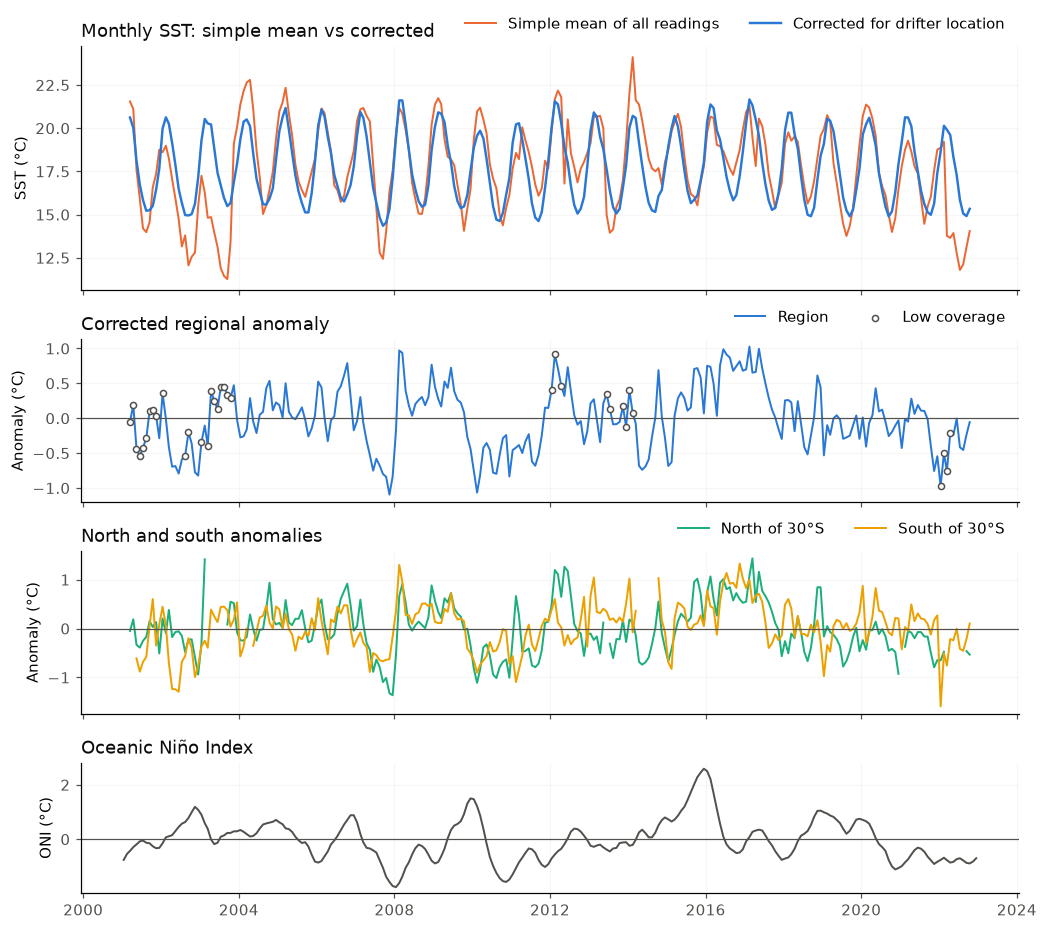

In [5]:
# Figure: the simple mean against the corrected series, with ONI on its own panel
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
m = sst_monthly

fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True,
                         gridspec_kw={"height_ratios": [1.5, 1, 1, 0.8], "hspace": 0.28})
ax = axes[0]
ax.plot(m["date"], m["sst_simple"], color=ORANGE, lw=1.3, label="Simple mean of all readings")
ax.plot(m["date"], m["sst_adjusted"], color=BLUE, lw=1.6, label="Corrected for drifter location")
ax.set_ylabel("SST (°C)")
ax.set_title("Monthly SST: simple mean vs corrected", loc="left", color=INK)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1), ncols=2)

ax = axes[1]
ax.plot(m["date"], m["sst_anom"], color=BLUE, lw=1.3, label="Region")
low = m[m["low_coverage"]]
ax.scatter(low["date"], low["sst_anom"], s=16, facecolors="white", edgecolors=MUTED, linewidths=1,
           zorder=3, label="Low coverage")
ax.set_ylabel("Anomaly (°C)")
ax.set_title("Corrected regional anomaly", loc="left", color=INK)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1), ncols=2)

ax = axes[2]
ax.plot(m["date"], m["sst_anom_north"], color=AQUA, lw=1.3, label=f"North of {abs(NORTH_SOUTH_SPLIT)}°S")
ax.plot(m["date"], m["sst_anom_south"], color=YELLOW, lw=1.3, label=f"South of {abs(NORTH_SOUTH_SPLIT)}°S")
ax.set_ylabel("Anomaly (°C)")
ax.set_title("North and south anomalies", loc="left", color=INK)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1), ncols=2)

ax = axes[3]
ax.plot(m["date"], m["oni"], color=MUTED, lw=1.3)
ax.set_ylabel("ONI (°C)")
ax.set_title("Oceanic Niño Index", loc="left", color=INK)

for ax in axes:
    ax.grid(True, color=GRID, lw=0.7)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(colors=MUTED)
for ax in axes[1:]:
    ax.axhline(0, color=MUTED, lw=0.8)
plt.show()


Correlation 0.967; RMS difference 1.02 C


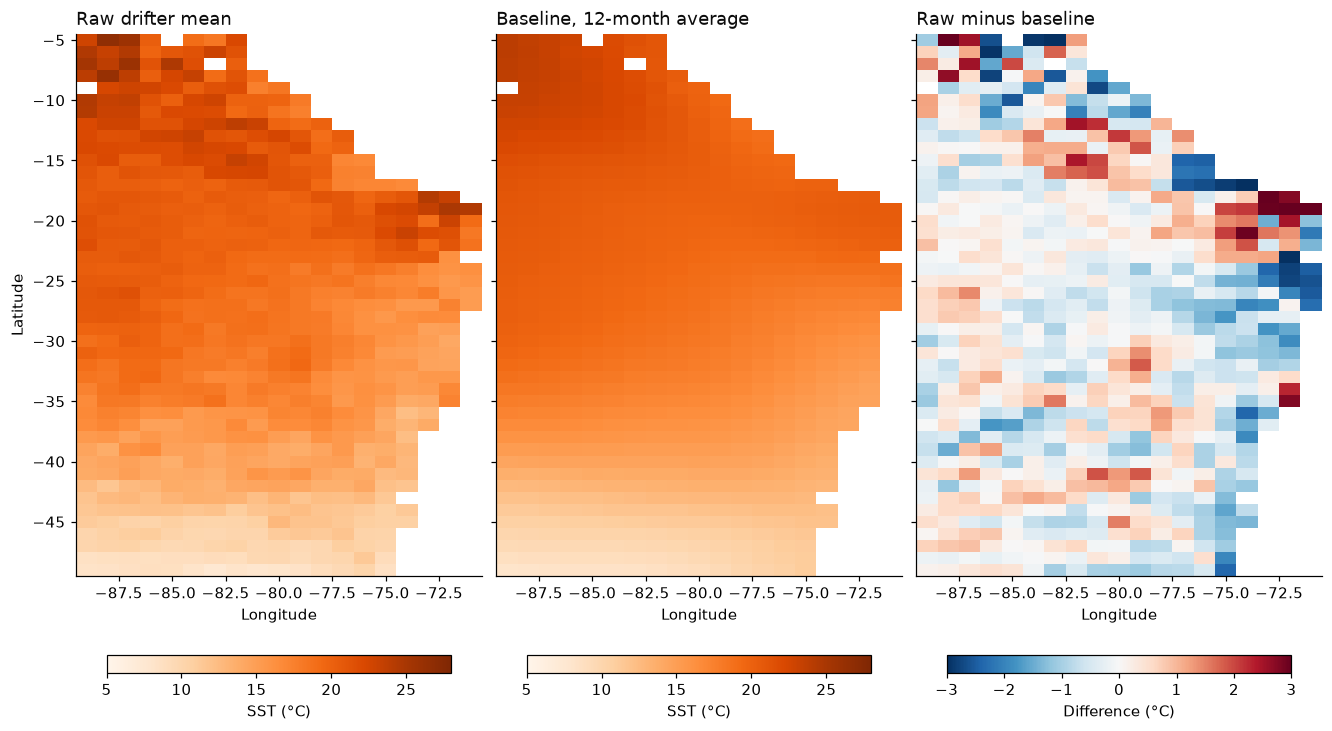

In [6]:
# Check the baseline's annual average against the raw 1-degree mean map
grid = (df.assign(cell_lat=np.floor(df["lat"]), cell_lon=np.floor(df["lon"]))
          .groupby(["cell_lat", "cell_lon"])
          .agg(lat=("lat", "mean"), lon=("lon", "mean"), raw=("sst_degC", "mean")).reset_index())
grid["baseline"] = np.mean([predict(beta_full, grid["lat"].to_numpy(), grid["lon"].to_numpy(),
                                    np.full(len(grid), d)) for d in mid_month_doy], axis=0)
grid["difference"] = grid["raw"] - grid["baseline"]
print(f"Correlation {grid['raw'].corr(grid['baseline']):.3f}; "
      f"RMS difference {np.sqrt((grid['difference'] ** 2).mean()):.2f} C")

panels = [("raw", "Raw drifter mean", "Oranges", 5, 28, "SST (°C)"),
          ("baseline", "Baseline, 12-month average", "Oranges", 5, 28, "SST (°C)"),
          ("difference", "Raw minus baseline", "RdBu_r", -3, 3, "Difference (°C)")]
fig, axes = plt.subplots(1, 3, figsize=(12, 6.5), sharex=True, sharey=True, constrained_layout=True)
for ax, (col, title, cmap, vmin, vmax, label) in zip(axes, panels):
    surface = grid.pivot(index="cell_lat", columns="cell_lon", values=col)
    mesh = ax.pcolormesh(surface.columns, surface.index, surface.to_numpy(), cmap=cmap, vmin=vmin, vmax=vmax,
                         shading="nearest")
    ax.set_title(title, loc="left", color=INK)
    ax.set_xlabel("Longitude")
    ax.grid(False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.colorbar(mesh, ax=ax, label=label, orientation="horizontal", shrink=0.85)
axes[0].set_ylabel("Latitude")
plt.show()


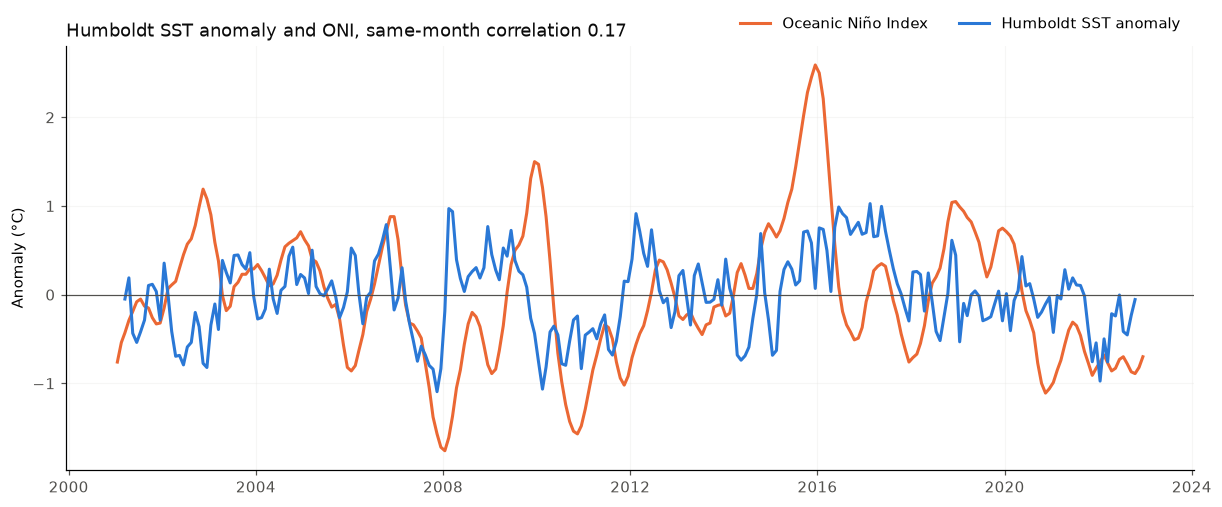

In [7]:
# Figure: regional SST anomaly against the Oceanic Niño Index, both in degrees C on one axis
same_month_corr = sst_monthly["sst_anom"].corr(sst_monthly["oni"])

fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
ax.plot(m["date"], m["oni"], color=ORANGE, lw=2, label="Oceanic Niño Index")
ax.plot(m["date"], m["sst_anom"], color=BLUE, lw=2, label="Humboldt SST anomaly")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_ylabel("Anomaly (°C)")
ax.set_title(f"Humboldt SST anomaly and ONI, same-month correlation {same_month_corr:.2f}", loc="left", color=INK)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1), ncols=2)
ax.grid(True, color=GRID, lw=0.7)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors=MUTED)
fig.savefig("../figures/sst_vs_oni.png", dpi=200)
plt.show()


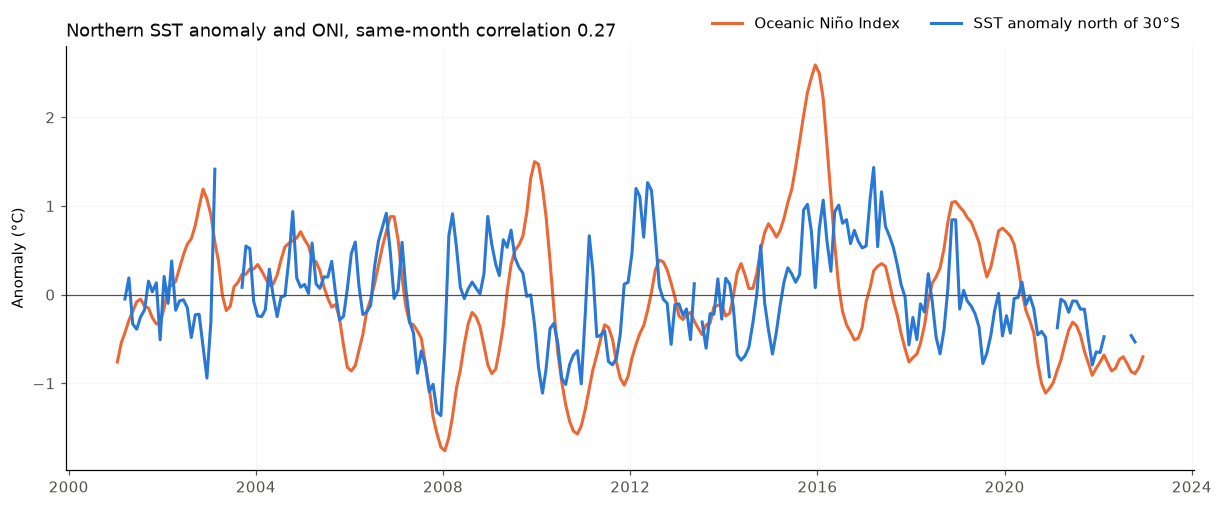

In [8]:
# Figure: SST anomaly north of the split against the Oceanic Niño Index, both in degrees C on one axis
north_corr = sst_monthly["sst_anom_north"].corr(sst_monthly["oni"])

fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
ax.plot(m["date"], m["oni"], color=ORANGE, lw=2, label="Oceanic Niño Index")
ax.plot(m["date"], m["sst_anom_north"], color=BLUE, lw=2, label=f"SST anomaly north of {abs(NORTH_SOUTH_SPLIT)}°S")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_ylabel("Anomaly (°C)")
ax.set_title(f"Northern SST anomaly and ONI, same-month correlation {north_corr:.2f}", loc="left", color=INK)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1), ncols=2)
ax.grid(True, color=GRID, lw=0.7)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors=MUTED)
fig.savefig("../figures/sst_north_vs_oni.png", dpi=200)
plt.show()


               type    start      end  months
0   Coastal La Niña  2001-06  2002-01       8
1   Coastal El Niño  2002-03  2002-05       3
2   Coastal El Niño  2002-10  2002-12       3
3   Coastal La Niña  2003-04  2003-07       4
4   Coastal La Niña  2004-04  2004-08       5
5   Coastal La Niña  2005-02  2005-05       4
6   Coastal La Niña  2005-07  2005-12       6
7   Coastal El Niño  2006-08  2007-01       6
8   Coastal La Niña  2007-04  2008-01      10
9   Coastal El Niño  2008-06  2008-10       5
10  Coastal El Niño  2009-05  2009-09       5
11  Coastal La Niña  2010-07  2011-01       7
12  Coastal La Niña  2011-09  2012-01       5
13  Coastal El Niño  2012-04  2012-07       4
14  Coastal La Niña  2013-03  2013-11       9
15  Coastal El Niño  2014-05  2014-10       6
16  Coastal El Niño  2015-04  2016-06      15
17  Coastal El Niño  2016-08  2016-10       3
18  Coastal El Niño  2016-12  2017-04       5
19  Coastal La Niña  2017-08  2018-06      11
20  Coastal El Niño  2018-11  2019

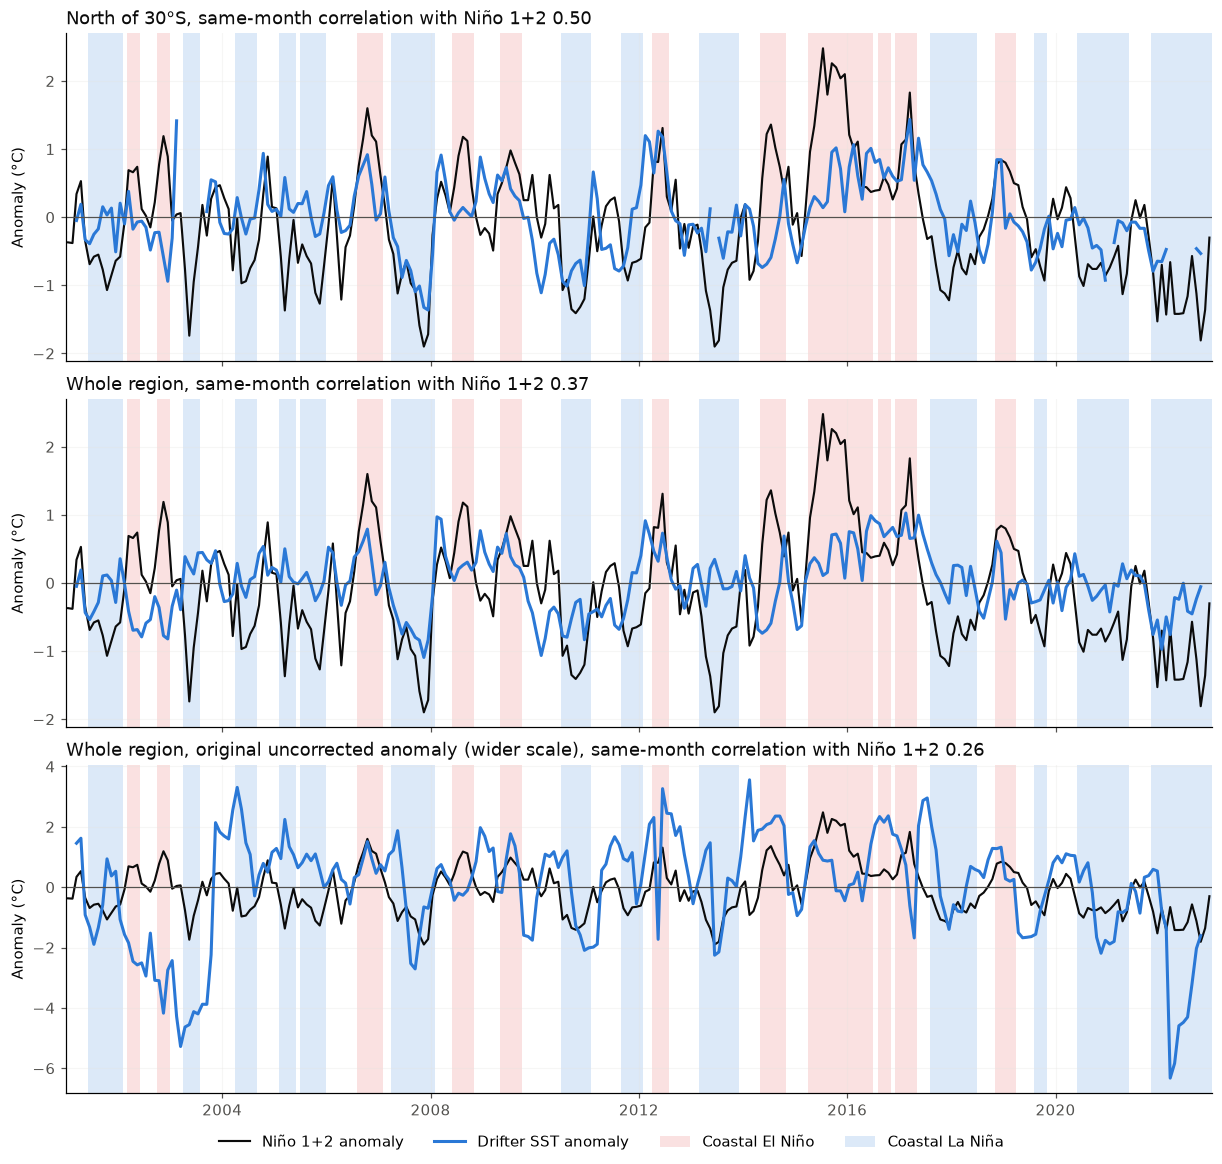

In [9]:
# Figure: north and whole-region SST anomalies against Niño 1+2, the index for waters off Peru and Ecuador
# sstoi.indices is NOAA CPC's monthly Niño SST file: https://www.cpc.ncep.noaa.gov/data/indices/sstoi.indices
RED = "#e34948"
COASTAL_WARM, COASTAL_COLD = 0.4, -0.4   # coastal El Niño >= +0.4 °C, coastal La Niña <= -0.4 °C
                                         # (was -1.0 for La Niña; now symmetric, matching the forecasting notebooks)
COASTAL_MIN_MONTHS = 3

nino = pd.read_csv("../data/raw/sstoi.indices", sep=r"\s+", skiprows=1,
                   names=["year", "month", "nino12", "nino12_anom", "nino3", "nino3_anom",
                          "nino4", "nino4_anom", "nino34", "nino34_anom"])
sst_monthly["nino12"] = nino.set_index(["year", "month"])["nino12_anom"].reindex(sst_monthly.index)
m = sst_monthly

# A coastal event is a run of at least 3 months with the 3-month mean of Niño 1+2 past the threshold
nino12_all = pd.Series(nino["nino12_anom"].to_numpy(),
                       index=pd.PeriodIndex.from_fields(year=nino["year"], month=nino["month"], freq="M"))
nino12_smooth = nino12_all.rolling(3, center=True).mean()


def coastal_events(active, kind):
    run_id = (active != active.shift()).cumsum()
    runs = [run.index for _, run in active[active].groupby(run_id[active]) if len(run) >= COASTAL_MIN_MONTHS]
    return [{"type": kind, "start": r[0], "end": r[-1], "months": len(r)} for r in runs]


coastal = pd.DataFrame(coastal_events(nino12_smooth >= COASTAL_WARM, "Coastal El Niño")
                       + coastal_events(nino12_smooth <= COASTAL_COLD, "Coastal La Niña"))
coastal = coastal[(coastal["end"] >= pd.Period("2001-01")) & (coastal["start"] <= pd.Period("2022-12"))]
coastal = coastal.sort_values("start").reset_index(drop=True)
print(coastal.to_string())

# The original anomaly: the simple monthly mean with only the seasonal cycle removed
sst_monthly["sst_simple_anom"] = deseason(sst_monthly["sst_simple"])

panels = [("sst_anom_north", f"North of {abs(NORTH_SOUTH_SPLIT)}°S"), ("sst_anom", "Whole region"),
          ("sst_simple_anom", "Whole region, original uncorrected anomaly (wider scale)")]
fig, axes = plt.subplots(3, 1, figsize=(11, 10.5), sharex=True, constrained_layout=True)
for ax, (column, label) in zip(axes, panels):
    for e in coastal.itertuples():
        ax.axvspan(e.start.start_time, e.end.end_time, linewidth=0, alpha=0.16,
                   color=RED if e.type == "Coastal El Niño" else BLUE)
    ax.plot(m["date"], m["nino12"], color=INK, lw=1.4, label="Niño 1+2 anomaly")
    ax.plot(m["date"], m[column], color=BLUE, lw=2, label="Drifter SST anomaly")
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_ylabel("Anomaly (°C)")
    ax.set_title(f"{label}, same-month correlation with Niño 1+2 {m[column].corr(m['nino12']):.2f}", loc="left", color=INK)
    ax.grid(True, color=GRID, lw=0.7)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(colors=MUTED)
lines, names = axes[0].get_legend_handles_labels()
shades = [plt.Rectangle((0, 0), 1, 1, color=RED, alpha=0.16, linewidth=0),
          plt.Rectangle((0, 0), 1, 1, color=BLUE, alpha=0.16, linewidth=0)]
fig.legend(lines + shades, names + ["Coastal El Niño", "Coastal La Niña"], frameon=False,
           loc="outside lower center", ncols=4)
axes[2].set_xlim(pd.Timestamp("2001-01-01"), pd.Timestamp("2023-01-01"))
axes[1].set_ylim(axes[0].get_ylim())
fig.savefig("../figures/sst_vs_nino12.png", dpi=200)
plt.show()


## Current response to El Niño and La Niña

Drifter velocity gives a direct measure of how the water moves. The method follows the SST work: a seasonal baseline for each velocity component, anomalies for each reading, then area-weighted monthly series.

**Only drogued readings are used.** After a drifter loses its drogue, wind pushes it directly, so its velocity no longer represents the current. About half of the readings are undrogued, and that share changes a lot from year to year.

`vn_anom` is the northward velocity anomaly. The Humboldt flows north, so a negative value means weaker flow. The current core is defined here as 15–40°S, east of 80°W.

In [10]:
# Velocity baselines from drogued readings only, one year left out at a time
DROGUE_FILE = CACHE / "drogue_lost_date.npy"
if not DROGUE_FILE.exists():
    from clouddrift.datasets import gdp1h
    np.save(DROGUE_FILE, gdp1h()["drogue_lost_date"].values)

drogue_lost = pd.Series(np.load(DROGUE_FILE), index=np.load(CACHE / "id.npy"))
df["drogued"] = df["time"] < df["id"].map(drogue_lost).to_numpy()
print(f"Drogued readings: {df['drogued'].mean():.0%}")

drogued = df[df["drogued"]]
vel_units = (drogued.assign(cell_lat=np.floor(drogued["lat"]), cell_lon=np.floor(drogued["lon"]))
                    .groupby(["cell_lat", "cell_lon", "year", "month"])
                    .agg(lat=("lat", "mean"), lon=("lon", "mean"), doy=("doy", "mean"),
                         ve=("ve", "mean"), vn=("vn", "mean"))
                    .reset_index())
vel_weight = (1 / vel_units.groupby("year")["vn"].transform("size")).to_numpy()
vel_weight = vel_weight * len(vel_units) / vel_weight.sum()

VELOCITIES = ["ve", "vn"]
XtWX_year, XtWy_year = {}, {}
for year in sorted(vel_units["year"].unique()):
    k = (vel_units["year"] == year).to_numpy()
    Xk, wk = design_matrix(vel_units["lat"].to_numpy()[k], vel_units["lon"].to_numpy()[k],
                           vel_units["doy"].to_numpy()[k]), vel_weight[k]
    XtWX_year[year], XtWy_year[year] = (Xk.T * wk) @ Xk, (Xk.T * wk) @ vel_units[VELOCITIES].to_numpy()[k]
XtWX, XtWy = sum(XtWX_year.values()), sum(XtWy_year.values())

for name in ["ve_anom", "vn_anom"]:
    df[name] = np.nan
for year, rows in drogued.groupby("year").indices.items():
    beta = np.linalg.solve(XtWX - XtWX_year[year] + penalty, XtWy - XtWy_year[year])
    labels = drogued.index[rows]
    lat, lon = drogued["lat"].to_numpy()[rows], drogued["lon"].to_numpy()[rows]
    doy = drogued["doy"].to_numpy()[rows].astype(float)
    for i, v in enumerate(VELOCITIES):
        df.loc[labels, f"{v}_anom"] = drogued[v].to_numpy()[rows] - predict(beta[:, i], lat, lon, doy)
del drogued

print(df[["ve_anom", "vn_anom"]].describe().round(3))

Drogued readings: 50%


           ve_anom      vn_anom
count  1268198.000  1268198.000
mean         0.016       -0.008
std          0.128        0.124
min         -1.491       -1.190
25%         -0.062       -0.085
50%          0.019       -0.009
75%          0.096        0.068
max          1.689        1.168


In [11]:
# Monthly velocity series, built the same way as sst_anom
CORE_LAT = (-40, -15)
CORE_EAST_OF = -80


def gridded_monthly(data, column):
    binned = data.assign(cell_lat=np.floor(data["lat"] / CELL_DEG) * CELL_DEG,
                         cell_lon=np.floor(data["lon"] / CELL_DEG) * CELL_DEG)
    c = (binned.groupby(["year", "month", "cell_lat", "cell_lon"])[column]
               .agg(anom="mean", n="size").reset_index())
    c = c[c["n"] >= MIN_READINGS].copy()
    c["area"] = np.cos(np.radians(c["cell_lat"] + CELL_DEG / 2))
    return area_mean(c).reindex(all_months)


good = df[df["drogued"]]
core = good[good["lat"].between(*CORE_LAT) & (good["lon"] > CORE_EAST_OF)]
north_drogued = good[good["lat"] >= NORTH_SOUTH_SPLIT]
sst_monthly["vn_anom_core"] = gridded_monthly(core, "vn_anom")
sst_monthly["ve_anom_core"] = gridded_monthly(core, "ve_anom")
sst_monthly["vn_anom_north"] = gridded_monthly(north_drogued, "vn_anom")
sst_monthly["ve_anom_north"] = gridded_monthly(north_drogued, "ve_anom")
sst_monthly["drogued_share"] = df.groupby(["year", "month"])["drogued"].mean()
del good, core, north_drogued

velocity_columns = ["vn_anom_core", "ve_anom_core", "vn_anom_north", "ve_anom_north"]
print(sst_monthly[velocity_columns].agg(["count", "std"]).round(3))
print(sst_monthly[velocity_columns].corrwith(sst_monthly["nino12"]).round(2).rename("Corr with Niño 1+2, same month"))

       vn_anom_core  ve_anom_core  vn_anom_north  ve_anom_north
count       180.000        180.00        217.000        217.000
std           0.048          0.06          0.037          0.048
vn_anom_core    -0.12
ve_anom_core     0.04
vn_anom_north   -0.01
ve_anom_north    0.02
Name: Corr with Niño 1+2, same month, dtype: float64


## Baseline forecasts once a coastal event is flagged

A coastal El Niño or La Niña is flagged once it has lasted 3 months. At months 3, 4 and 5 we forecast the event's **total length**, its **peak SST anomaly** (north of 30°S, from the drifters) and its **mean northward-velocity anomaly** in the current core. Anomalies are signed so that positive means the expected response. La Niña events are sign-flipped and pooled with El Niño, because 5 La Niña events are too few on their own.

Events are flagged with a **trailing** 3-month mean of Niño 1+2. The centered mean used above looks one month ahead, which a forecast can't do.

With about 16 events, the baseline fits no parameters. It uses the past events that also lasted at least *k* months (its "analogs"):
- **Length:** the median length of the analogs.
- **Peak SST:** the peak so far, plus the median further rise the analogs showed after month *k*.
- **Velocity:** the months so far at their observed mean, and the predicted remaining months at the analogs' mean for those later months.

It is scored against **climatology** (the average of all other events) and **persistence** (the event ends now). Every forecast is leave-one-event-out. Skill = 1 − MAE / MAE of climatology.

**How to read the result.** Length is the hard target: the baseline only just beats climatology. For peak SST the analogs' median further rise is 0, so the drifter SST has usually peaked by the time the event is flagged, and the baseline equals persistence. Velocity skill is high mostly because the months already observed make up much of a short event's mean. This is the bar a real model has to clear.

               type    start      end  months
0   Coastal La Niña  2001-07  2002-02       8
1   Coastal El Niño  2002-04  2002-06       3
2   Coastal El Niño  2002-11  2003-01       3
3   Coastal La Niña  2003-05  2003-08       4
4   Coastal La Niña  2004-05  2004-09       5
5   Coastal La Niña  2005-03  2005-06       4
6   Coastal La Niña  2005-08  2006-01       6
7   Coastal El Niño  2006-09  2007-02       6
8   Coastal La Niña  2007-05  2008-02      10
9   Coastal El Niño  2008-07  2008-11       5
10  Coastal El Niño  2009-06  2009-10       5
11  Coastal La Niña  2010-08  2011-02       7
12  Coastal La Niña  2011-10  2012-02       5
13  Coastal El Niño  2012-05  2012-08       4
14  Coastal La Niña  2013-04  2013-12       9
15  Coastal El Niño  2014-06  2014-11       6
16  Coastal El Niño  2015-05  2016-07      15
17  Coastal El Niño  2016-09  2016-11       3
18  Coastal El Niño  2017-01  2017-05       5
19  Coastal La Niña  2017-09  2018-07      11
20  Coastal El Niño  2018-12  2019

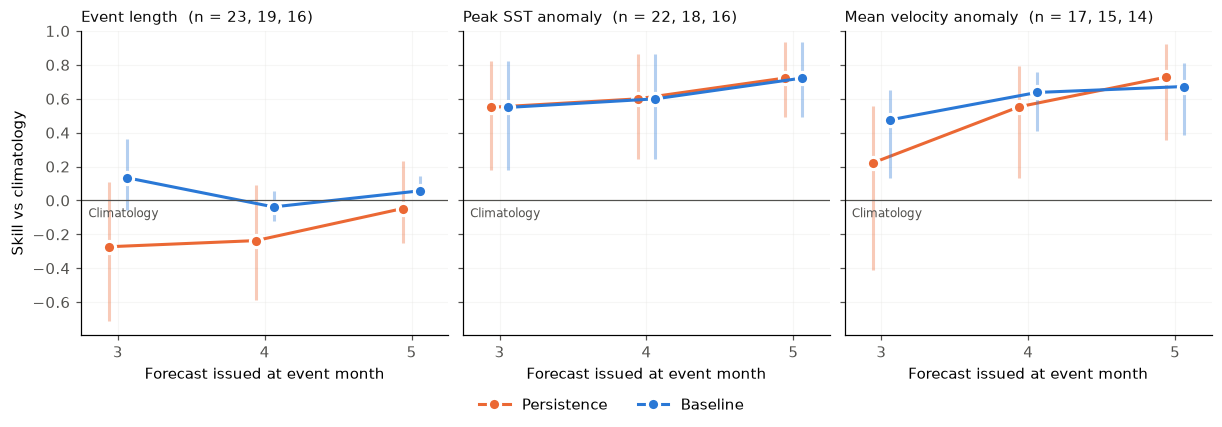

In [12]:
# ============================================================================
# BASELINE FORECASTS FOR COASTAL EVENTS, ISSUED 3, 4 AND 5 MONTHS IN
#
# A coastal event is flagged once it has lasted 3 months. At months 3, 4 and 5
# we forecast three things about the whole event:
#   duration   total length in months
#   sst_peak   peak drifter SST anomaly north of 30S (3-month trailing mean, C)
#   vn_mean    mean drifter northward-velocity anomaly in the current core (m/s)
# Anomalies are signed so that positive means the expected response
# (warmer and weaker northward flow in El Niño; the reverse in La Niña).
#
# There are only about 15 events, so the baseline fits no parameters:
#   duration   median length of the past events that also lasted at least k months
#   sst_peak   peak so far + median further rise those past events showed after month k
#   vn_mean    months so far at their observed mean, plus the predicted remaining
#              months at the past events' mean for their months after k
# Two references show whether the baseline adds anything:
#   climatology  mean of all other events, ignoring that this one has lasted k months
#   persistence  the event ends now: duration k, peak = peak so far, vn = mean so far
# Every forecast is leave-one-event-out: an event is never in its own analog set.
# ============================================================================
FORECAST_MONTHS = [3, 4, 5]
TARGETS = ["duration", "sst_peak", "vn_mean"]
METHODS = ["climatology", "persistence", "baseline"]
N_BOOT = 2000

# Monthly series indexed by month, so event windows can be sliced by date
tracked = sst_monthly.set_index(pd.PeriodIndex(sst_monthly["date"], freq="M"))

# Real-time flag: a TRAILING 3-month mean, so a forecast at month k uses data up to month k only.
# (The centered mean used for the `coastal` table looks one month ahead.)
nino12_trailing = nino12_all.rolling(3).mean()
rt_events = pd.DataFrame(coastal_events(nino12_trailing >= COASTAL_WARM, "Coastal El Niño")
                         + coastal_events(nino12_trailing <= COASTAL_COLD, "Coastal La Niña"))
# Keep events that fall entirely inside the drifter record
rt_events = rt_events[(rt_events["start"] >= tracked.index[0]) & (rt_events["end"] <= tracked.index[-1])]
rt_events = rt_events.sort_values("start").reset_index(drop=True)

sst_trailing = tracked["sst_anom_north"].rolling(3, min_periods=2).mean()
vn_monthly = tracked["vn_anom_core"]


def nanmax(x):
    x = np.asarray(x, dtype=float)
    return np.nan if np.isnan(x).all() else np.nanmax(x)


def nanmean(x):
    x = np.asarray(x, dtype=float)
    return np.nan if np.isnan(x).all() else np.nanmean(x)


def event_record(e):
    sign = 1 if e.type == "Coastal El Niño" else -1
    months = pd.period_range(e.start, e.end, freq="M")
    sst = sign * sst_trailing.reindex(months).to_numpy()
    vn = -sign * vn_monthly.reindex(months).to_numpy()
    return {"type": e.type, "start": e.start, "duration": e.months, "sst": sst, "vn": vn,
            "sst_peak": nanmax(sst), "vn_mean": nanmean(vn)}


records = [event_record(e) for e in rt_events.itertuples()]


def forecast(train, test, k):
    """All three methods' forecasts for `test`, issued at month k, using only `train`."""
    sst_so_far, vn_so_far = nanmax(test["sst"][:k]), nanmean(test["vn"][:k])
    clim = {t: nanmean([r[t] for r in train]) for t in TARGETS}

    analogs = [r for r in train if r["duration"] >= k]
    duration = float(np.median([r["duration"] for r in analogs]))
    rises = np.array([r["sst_peak"] - nanmax(r["sst"][:k]) for r in analogs])
    rise = np.median(rises[~np.isnan(rises)]) if (~np.isnan(rises)).any() else 0.0
    later_vn = nanmean([nanmean(r["vn"][k:]) for r in analogs if r["duration"] > k])
    remaining = max(duration - k, 0.0)
    if np.isnan(vn_so_far):
        vn_base = later_vn
    elif remaining == 0 or np.isnan(later_vn):
        vn_base = vn_so_far
    else:
        vn_base = (k * vn_so_far + remaining * later_vn) / (k + remaining)

    return {
        "climatology": clim,
        "persistence": {"duration": k, "sst_peak": sst_so_far, "vn_mean": vn_so_far},
        "baseline": {"duration": duration, "sst_peak": sst_so_far + rise, "vn_mean": vn_base},
    }


def run_forecasts(pool):
    rows = []
    for i, test in enumerate(pool):
        train = pool[:i] + pool[i + 1:]
        for k in FORECAST_MONTHS:
            if test["duration"] < k:      # already over, nothing to forecast
                continue
            f = forecast(train, test, k)
            for t in TARGETS:
                rows.append({"start": test["start"], "type": test["type"], "k": k, "target": t,
                             "observed": test[t], **{m: f[m][t] for m in METHODS}})
    out = pd.DataFrame(rows)
    # Score each target only where every method and the observation exist
    return out.dropna(subset=["observed"] + METHODS)


def skill_table(fc):
    rows = []
    for (k, t), g in fc.groupby(["k", "target"]):
        err = {m: (g[m] - g["observed"]).abs().to_numpy() for m in METHODS}
        picks = rng.integers(0, len(g), (N_BOOT, len(g)))
        clim_boot = err["climatology"][picks].mean(axis=1)
        for m in METHODS:
            boot = 1 - err[m][picks].mean(axis=1) / clim_boot
            rows.append({"k": k, "target": t, "method": m, "n": len(g), "mae": err[m].mean(),
                         "skill": 1 - err[m].mean() / err["climatology"].mean(),
                         "skill_lo": np.nanquantile(boot, 0.025), "skill_hi": np.nanquantile(boot, 0.975)})
    return pd.DataFrame(rows)


rng = np.random.default_rng(0)
pools = {"Pooled (La Niña sign-flipped)": records,
         "El Niño only": [r for r in records if r["type"] == "Coastal El Niño"]}
forecasts = {name: run_forecasts(pool) for name, pool in pools.items()}
skills = {name: skill_table(fc) for name, fc in forecasts.items()}

print(rt_events.to_string())
print(f"\nEvents still running at month k: "
      + ", ".join(f"k={k}: {sum(r['duration'] >= k for r in records)}" for k in FORECAST_MONTHS))
for name, s in skills.items():
    print(f"\n{name}: mean absolute error, and skill vs climatology (1 = perfect, 0 = no better, <0 worse)")
    table = s.pivot_table(index=["target", "k"], columns="method", values=["mae", "skill"])
    table.insert(0, "n", s.groupby(["target", "k"])["n"].first())
    print(table.round(3).to_string())

# Figure: skill against forecast month, one panel per target (pooled events)
s = skills["Pooled (La Niña sign-flipped)"]
titles = {"duration": "Event length", "sst_peak": "Peak SST anomaly", "vn_mean": "Mean velocity anomaly"}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True, constrained_layout=True)
for ax, t in zip(axes, TARGETS):
    for m, color, offset in [("persistence", ORANGE, -0.06), ("baseline", BLUE, 0.06)]:
        g = s[(s["target"] == t) & (s["method"] == m)].sort_values("k")
        x = g["k"] + offset
        ax.vlines(x, g["skill_lo"], g["skill_hi"], color=color, lw=2, alpha=0.35)
        ax.plot(x, g["skill"], color=color, lw=2, marker="o", ms=8, mec="white", mew=2, label=m.capitalize())
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.text(2.8, -0.04, "Climatology", color=MUTED, va="top", ha="left", fontsize=8)
    n = s[(s["target"] == t) & (s["method"] == "baseline")].sort_values("k")["n"].tolist()
    ax.set_title(f"{titles[t]}  (n = {', '.join(map(str, n))})", loc="left", color=INK, fontsize=10)
    ax.set_xticks(FORECAST_MONTHS)
    ax.set_xlim(2.75, 5.25)
    ax.set_xlabel("Forecast issued at event month")
    ax.grid(True, color=GRID, lw=0.7)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(colors=MUTED)
axes[0].set_ylabel("Skill vs climatology")
axes[0].set_ylim(max(axes[0].get_ylim()[0], -3), 1)
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, loc="outside lower center", ncols=2)
fig.savefig("../figures/fig3_forecast_skill.png", dpi=200)
plt.show()


## Fish catch and coastal El Niño / La Niña

Yearly Humboldt Current catch (Sea Around Us, LME 13) for the four largest species, with the coastal events from Niño 1+2 shaded. Run the Niño 1+2 cell above first: this cell reuses `coastal_events`, `nino12_smooth` and the thresholds. It needs `openpyxl` to read the Excel file.

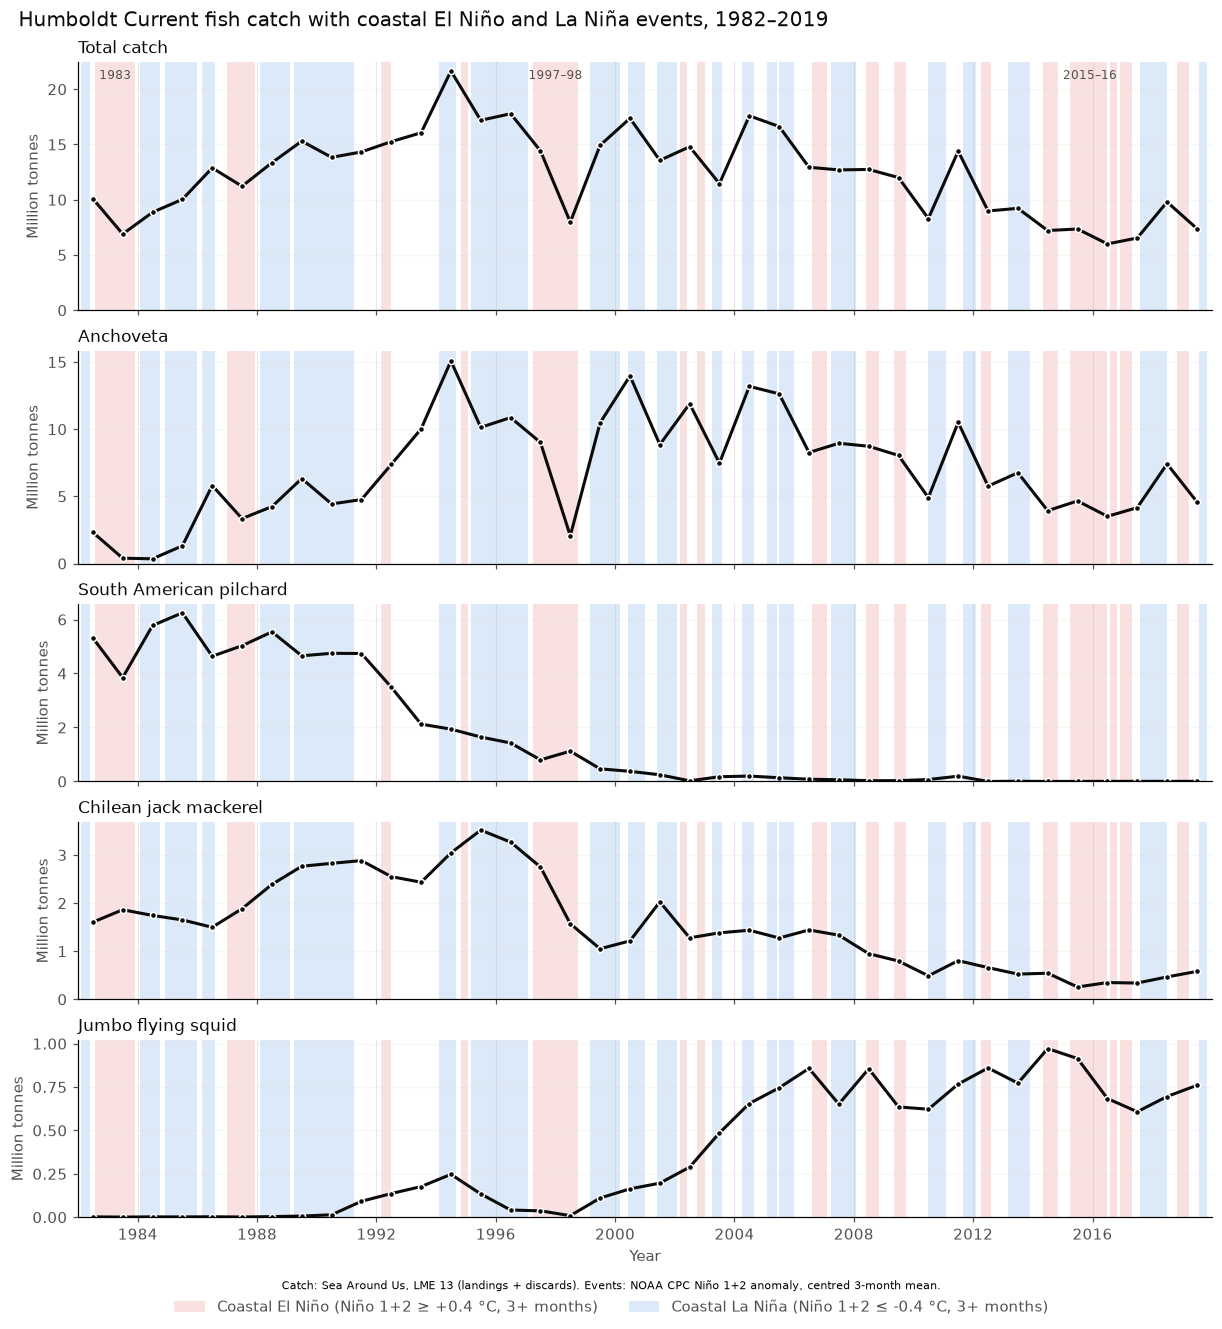

In [13]:
# Figure: yearly fish catch with coastal El Niño and La Niña events from Niño 1+2
# Catch: Sea Around Us, Humboldt Current LME 13 (data/raw/fish_data/fish_data.xlsx, from the group repo's main branch).
# Events use the same rule as the `coastal` table above (centred 3-month Niño 1+2 mean past
# COASTAL_WARM / COASTAL_COLD for at least COASTAL_MIN_MONTHS), over the full Niño 1+2 record.
FISH_START, FISH_END = 1982, 2019   # Niño 1+2 starts in 1982; the catch data ends in 2019
FISH_SPECIES = ["Anchoveta", "South American pilchard", "Chilean jack mackerel", "Jumbo flying squid"]

catch_raw = pd.read_excel("../data/raw/fish_data/fish_data.xlsx", sheet_name="SAU LME 13 v50-1")
catch_raw = catch_raw[catch_raw["year"].between(FISH_START, FISH_END)]
fish_years = pd.RangeIndex(FISH_START, FISH_END + 1, name="year")
catch_by_species = (catch_raw.groupby(["year", "common_name"])["tonnes"].sum()
                             .unstack().reindex(fish_years).fillna(0))
fish_panels = [("Total catch", catch_raw.groupby("year")["tonnes"].sum().reindex(fish_years))]
fish_panels += [(sp, catch_by_species[sp]) for sp in FISH_SPECIES]

fish_events = pd.DataFrame(coastal_events(nino12_smooth >= COASTAL_WARM, "Coastal El Niño")
                           + coastal_events(nino12_smooth <= COASTAL_COLD, "Coastal La Niña"))
fish_events = fish_events[(fish_events["end"].dt.year >= FISH_START) & (fish_events["start"].dt.year <= FISH_END)]
fish_events = fish_events.sort_values("start").reset_index(drop=True)

window = (pd.Timestamp(f"{FISH_START}-01-01"), pd.Timestamp(f"{FISH_END}-12-31"))
mid_year = pd.to_datetime([f"{y}-07-01" for y in fish_years])

fig, axes = plt.subplots(len(fish_panels), 1, figsize=(11, 12), sharex=True, constrained_layout=True,
                         gridspec_kw={"height_ratios": [1.4, 1.2, 1, 1, 1]})
for ax, (name, tonnes) in zip(axes, fish_panels):
    for e in fish_events.itertuples():
        ax.axvspan(max(e.start.start_time, window[0]), min(e.end.end_time, window[1]), linewidth=0,
                   alpha=0.16, color=RED if e.type == "Coastal El Niño" else BLUE)
    ax.plot(mid_year, tonnes / 1e6, color=INK, lw=2, marker="o", ms=4, mec="white", mew=1)
    ax.set_ylim(bottom=0)
    ax.set_title(name, loc="left", color=INK, fontsize=11)
    ax.set_ylabel("Million tonnes", color=MUTED)
    ax.grid(True, axis="y", color=GRID, lw=0.7)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(colors=MUTED)
axes[-1].set_xlim(*window)
axes[-1].set_xlabel("Year", color=MUTED)
for label, when in [("1983", "1983-04-01"), ("1997–98", "1998-01-01"), ("2015–16", "2015-12-01")]:
    axes[0].annotate(label, (pd.Timestamp(when), axes[0].get_ylim()[1] * 0.97),
                     ha="center", va="top", fontsize=8, color=MUTED)
fig.suptitle(f"Humboldt Current fish catch with coastal El Niño and La Niña events, {FISH_START}–{FISH_END}",
             x=0.01, ha="left", color=INK, fontsize=13)
shades = [plt.Rectangle((0, 0), 1, 1, color=RED, alpha=0.16, linewidth=0),
          plt.Rectangle((0, 0), 1, 1, color=BLUE, alpha=0.16, linewidth=0)]
fig.legend(shades, [f"Coastal El Niño (Niño 1+2 ≥ +{COASTAL_WARM} °C, {COASTAL_MIN_MONTHS}+ months)",
                    f"Coastal La Niña (Niño 1+2 ≤ {COASTAL_COLD} °C, {COASTAL_MIN_MONTHS}+ months)"],
           frameon=False, loc="outside lower center", ncols=2, labelcolor=MUTED,
           title="Catch: Sea Around Us, LME 13 (landings + discards). Events: NOAA CPC Niño 1+2 anomaly, centred 3-month mean.",
           title_fontsize=7.5)
fig.savefig("../figures/fish_catch_coastal_enso.png", dpi=200, bbox_inches="tight", pad_inches=0.2)
plt.show()

## Fish catch against the drifter SST anomaly

Yearly catch for the main species set against the location-corrected drifter SST anomaly (`sst_anom`). The thick line is the yearly average of good-coverage months, which is what the catch is compared with. Run the SST, Niño 1+2 and fish cells above first. The catch data ends in 2019.

Same-year correlation of yearly catch change with the drifter SST anomaly


Total catch             -0.06
Anchoveta               -0.07
Chilean jack mackerel    0.11
Jumbo flying squid      -0.27

SST anomaly vs detrended anchoveta, same year: r = -0.13 (17 years)


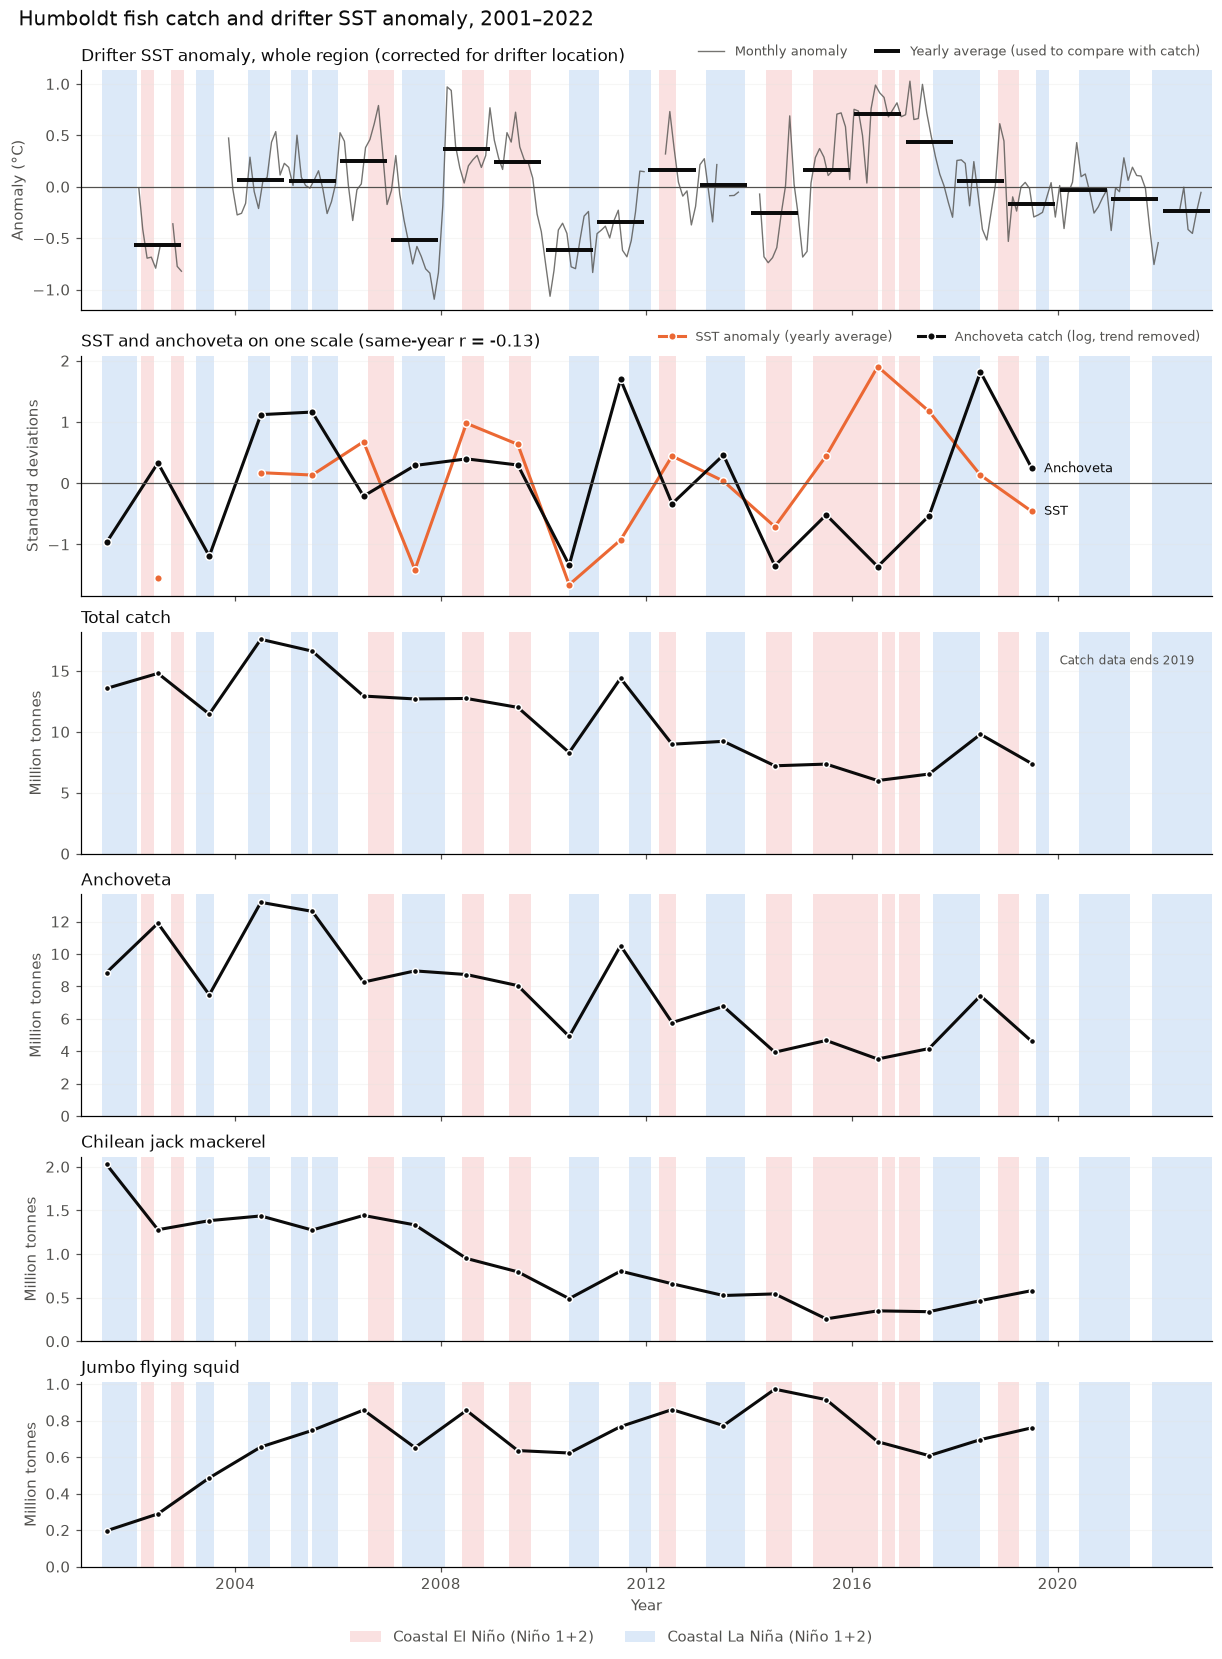

In [14]:
# Figure: fish catch against the location-corrected drifter SST anomaly (sst_monthly), 2001–2022
# Needs the SST cell (sst_monthly), the Niño 1+2 cell (coastal events) and the fish cell above (catch_raw).
# The catch data ends in 2019; the drifter SST runs to 2022.
MAP_START, MAP_END = 2001, 2022
MAP_SPECIES = ["Anchoveta", "Chilean jack mackerel", "Jumbo flying squid"]   # pilchard is near zero after 2001
MIN_GOOD_MONTHS = 6

# Yearly SST anomaly: mean of months with good coverage, needing at least 6 such months
good_sst = sst_monthly["sst_anom"].where(~sst_monthly["low_coverage"])
sst_year = good_sst.groupby(level="year").mean().where(good_sst.groupby(level="year").count() >= MIN_GOOD_MONTHS)
sst_year = sst_year.loc[MAP_START:MAP_END]

map_years = pd.RangeIndex(MAP_START, MAP_END + 1, name="year")
catch_map = catch_raw[catch_raw["year"] >= MAP_START]
species_map = catch_map.groupby(["year", "common_name"])["tonnes"].sum().unstack().reindex(map_years)
map_panels = [("Total catch", catch_map.groupby("year")["tonnes"].sum().reindex(map_years))]
map_panels += [(sp, species_map[sp]) for sp in MAP_SPECIES]

# Merged yearly table: catch alongside the drifter SST anomaly
fish_sst = pd.DataFrame({"sst_anom": sst_year, **{name: t for name, t in map_panels}}).loc[MAP_START:2019]
change = np.log(fish_sst.drop(columns="sst_anom")).diff()        # year-to-year change removes the trend
print("Same-year correlation of yearly catch change with the drifter SST anomaly")
print(change.corrwith(fish_sst["sst_anom"], method="spearman").round(2).to_string())

# SST and anchoveta on one axis: both as z-scores (standard deviations from their own mean).
# Anchoveta is log-transformed and detrended first, so the panel shows year-to-year swings, not the long decline.
anch_log = np.log(fish_sst["Anchoveta"])
fish_years_arr = fish_sst.index.to_numpy()
anch_detrended = anch_log - np.polyval(np.polyfit(fish_years_arr, anch_log, 1), fish_years_arr)
zscore = lambda s: (s - s.mean()) / s.std()
together = pd.DataFrame({"sst": zscore(fish_sst["sst_anom"]), "anchoveta": zscore(anch_detrended)})
together_r = together["sst"].corr(together["anchoveta"])
print(f"\nSST anomaly vs detrended anchoveta, same year: r = {together_r:.2f} "
      f"({together.dropna().shape[0]} years)")

map_window = (pd.Timestamp(f"{MAP_START}-01-01"), pd.Timestamp(f"{MAP_END}-12-31"))
map_events = coastal[(coastal["end"].dt.year >= MAP_START) & (coastal["start"].dt.year <= MAP_END)]
year_mid = pd.to_datetime([f"{y}-07-01" for y in map_years])

fig, axes = plt.subplots(len(map_panels) + 2, 1, figsize=(11, 15), sharex=True, constrained_layout=True,
                         gridspec_kw={"height_ratios": [1.3, 1.3, 1.2, 1.2, 1, 1]})
for ax in axes:
    for e in map_events.itertuples():
        ax.axvspan(max(e.start.start_time, map_window[0]), min(e.end.end_time, map_window[1]), linewidth=0,
                   alpha=0.16, color=RED if e.type == "Coastal El Niño" else BLUE)

ax = axes[0]
monthly_sst = good_sst.loc[MAP_START:MAP_END]
ax.plot(sst_monthly.loc[MAP_START:MAP_END, "date"], monthly_sst, color=MUTED, lw=0.9, alpha=0.8,
        label="Monthly anomaly")
ax.hlines(sst_year.to_numpy(), pd.to_datetime([f"{y}-01-15" for y in sst_year.index]),
          pd.to_datetime([f"{y}-12-15" for y in sst_year.index]), color=INK, lw=2.6,
          label="Yearly average (used to compare with catch)")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_title("Drifter SST anomaly, whole region (corrected for drifter location)", loc="left", color=INK, fontsize=11)
ax.set_ylabel("Anomaly (°C)", color=MUTED)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1), ncols=2, fontsize=8.5, labelcolor=MUTED)

ax = axes[1]
together_x = pd.to_datetime([f"{y}-07-01" for y in together.index])
ax.plot(together_x, together["sst"], color=ORANGE, lw=2, marker="o", ms=5, mec="white", mew=1,
        label="SST anomaly (yearly average)")
ax.plot(together_x, together["anchoveta"], color=INK, lw=2, marker="o", ms=5, mec="white", mew=1,
        label="Anchoveta catch (log, trend removed)")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_title(f"SST and anchoveta on one scale (same-year r = {together_r:.2f})", loc="left", color=INK, fontsize=11)
ax.set_ylabel("Standard deviations", color=MUTED)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1), ncols=2, fontsize=8.5, labelcolor=MUTED)
last = together.dropna().index[-1]
for col, label, color in [("sst", "SST", ORANGE), ("anchoveta", "Anchoveta", INK)]:
    ax.annotate(label, (pd.Timestamp(f"{last}-07-01"), together.loc[last, col]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=8.5, color=INK)

for ax, (name, tonnes) in zip(axes[2:], map_panels):
    ax.plot(year_mid, tonnes / 1e6, color=INK, lw=2, marker="o", ms=4, mec="white", mew=1)
    ax.set_ylim(bottom=0)
    ax.set_title(name, loc="left", color=INK, fontsize=11)
    ax.set_ylabel("Million tonnes", color=MUTED)
for ax in axes:
    ax.grid(False, axis="x")
    ax.grid(True, axis="y", color=GRID, lw=0.7)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(colors=MUTED)
axes[-1].set_xlim(*map_window)
axes[-1].set_xlabel("Year", color=MUTED)
axes[2].annotate("Catch data ends 2019", (pd.Timestamp("2020-01-15"), axes[2].get_ylim()[1] * 0.9),
                 fontsize=8, color=MUTED, va="top")
fig.suptitle(f"Humboldt fish catch and drifter SST anomaly, {MAP_START}–{MAP_END}", x=0.01, ha="left",
             color=INK, fontsize=13)
fig.legend([plt.Rectangle((0, 0), 1, 1, color=RED, alpha=0.16, linewidth=0),
            plt.Rectangle((0, 0), 1, 1, color=BLUE, alpha=0.16, linewidth=0)],
           ["Coastal El Niño (Niño 1+2)", "Coastal La Niña (Niño 1+2)"], frameon=False,
           loc="outside lower center", ncols=2, labelcolor=MUTED)
fig.savefig("../figures/fish_vs_drifter_sst.png", dpi=200, bbox_inches="tight", pad_inches=0.2)
plt.show()

## Forecasting anchoveta catch: linear models and ARIMA

Predicts each year's anchoveta catch from last year's catch and the drifter SST anomaly (linear models), and from the catch history alone (ARIMA). Each is tested against persistence. Run the fish cell and the fish-vs-SST cell above first.

ARIMA order chosen by AIC each year: [(0, 1, 1)]
Years used: 2005–2019 (15); forecast years: 2011–2019 (9)

Out-of-sample errors (each year predicted from earlier years only)
                        MAE (log)  Typical error (%)  MAE (million t)  Skill vs persistence
Persistence                 0.416             51.529            2.530                 0.000
Catch only                  0.421             52.349            2.555                -0.013
Catch + SST (forecast)      0.436             54.718            2.652                -0.050
Catch + SST (nowcast)       0.443             55.662            2.747                -0.065
ARIMA                       0.301             35.134            1.799                 0.276

Catch + SST (forecast), fitted on all years
               Coef.  Std.Err.  P>|t|
const          8.985     3.687  0.031
log_anch_lag1  0.425     0.234  0.094
sst_lag1      -0.189     0.275  0.506
R² = 0.27, n = 15. +1 °C of SST anomaly goes with a -17% change in next year

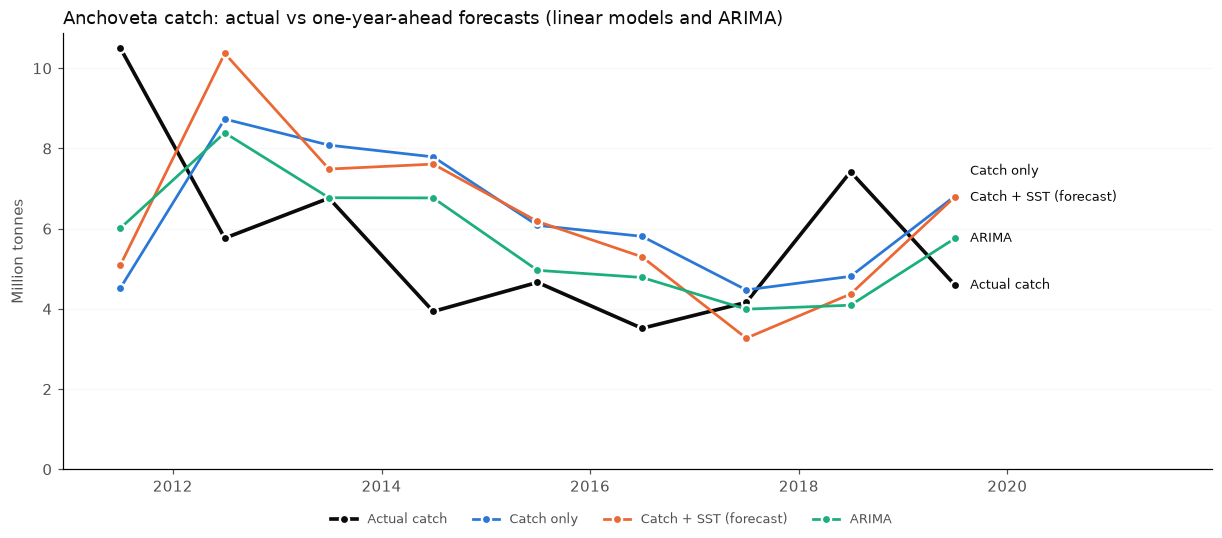

In [15]:
# ============================================================================
# LINEAR MODEL: PREDICT ANCHOVETA CATCH FROM LAGGED CATCH AND DRIFTER SST
# Needs the fish-vs-SST cell above (fish_sst: yearly catch + drifter SST anomaly).
#
# Target: log anchoveta catch in year t (log, so errors are proportional).
# Models, all fitted by ordinary least squares:
#   persistence     catch(t) = catch(t-1), no fitting; the reference to beat
#   catch only      log catch(t) ~ log catch(t-1)
#   catch + SST     log catch(t) ~ log catch(t-1) + SST anomaly(t-1)
#                   (a true forecast: everything is known before year t starts)
#   catch + SST now log catch(t) ~ log catch(t-1) + SST anomaly(t)
#                   (a nowcast: needs the SST of the year being predicted)
#   ARIMA           log catch(t) from the catch history alone. It uses the full catch
#                   record from 1982 (catch_raw, fish cell), still only years before t.
#                   The order is chosen by AIC in every training window, so the test
#                   years never influence the choice.
# Testing: expanding window. Each year is predicted by a model trained only on
# earlier years, so no future data leaks in. All models are scored on the same years.
# ============================================================================
import warnings
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA

MIN_TRAIN_YEARS = 6

anch = pd.DataFrame({"log_anch": np.log(fish_sst["Anchoveta"]), "sst": fish_sst["sst_anom"]})
anch["log_anch_lag1"] = anch["log_anch"].shift(1)
anch["sst_lag1"] = anch["sst"].shift(1)
anch = anch.dropna()            # years with every input (SST is missing for 2001 and 2003)

anch_models = {
    "Catch only": ["log_anch_lag1"],
    "Catch + SST (forecast)": ["log_anch_lag1", "sst_lag1"],
    "Catch + SST (nowcast)": ["log_anch_lag1", "sst"],
}

rows = []
for i in range(MIN_TRAIN_YEARS, len(anch)):
    train, test = anch.iloc[:i], anch.iloc[[i]]
    row = {"year": test.index[0], "actual": test["log_anch"].iloc[0],
           "Persistence": test["log_anch_lag1"].iloc[0]}
    for name, inputs in anch_models.items():
        fit = sm.OLS(train["log_anch"], sm.add_constant(train[inputs])).fit()
        row[name] = fit.predict(sm.add_constant(test[inputs], has_constant="add")).iloc[0]
    rows.append(row)
anch_pred = pd.DataFrame(rows).set_index("year")

# ARIMA on the long catch history, refitted for each forecast year
ARIMA_CANDIDATES = [((1, 0, 0), "c"), ((2, 0, 0), "c"), ((1, 0, 1), "c"),
                    ((0, 1, 1), "n"), ((1, 1, 0), "n"), ((1, 1, 1), "n")]
anch_history = np.log(catch_raw[catch_raw["common_name"] == "Anchoveta"].groupby("year")["tonnes"].sum())
anch_history.index = pd.PeriodIndex(anch_history.index.astype(str), freq="Y")
arima_orders = {}
for year in anch_pred.index:
    train = anch_history[anch_history.index.year < year]
    fits = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for order, trend in ARIMA_CANDIDATES:
            try:
                fits.append(ARIMA(train, order=order, trend=trend).fit())
            except (ValueError, np.linalg.LinAlgError):
                continue
    best = min(fits, key=lambda f: f.aic)
    arima_orders[year] = best.model.order
    anch_pred.loc[year, "ARIMA"] = best.forecast(1).iloc[0]
print("ARIMA order chosen by AIC each year:", sorted(set(arima_orders.values())))

methods = ["Persistence", *anch_models, "ARIMA"]
log_err = anch_pred[methods].sub(anch_pred["actual"], axis=0)
tonnes_err = np.exp(anch_pred[methods]).sub(np.exp(anch_pred["actual"]), axis=0) / 1e6
anch_scores = pd.DataFrame({
    "MAE (log)": log_err.abs().mean(),
    "Typical error (%)": (np.exp(log_err.abs().mean()) - 1) * 100,
    "MAE (million t)": tonnes_err.abs().mean(),
    "Skill vs persistence": 1 - log_err.abs().mean() / log_err["Persistence"].abs().mean(),
})
print(f"Years used: {anch.index.min()}–{anch.index.max()} ({len(anch)}); "
      f"forecast years: {anch_pred.index.min()}–{anch_pred.index.max()} ({len(anch_pred)})")
print("\nOut-of-sample errors (each year predicted from earlier years only)")
print(anch_scores.round(3).to_string())

# The full-sample fit, to read the coefficients (not a test of skill)
full_fit = sm.OLS(anch["log_anch"], sm.add_constant(anch[anch_models["Catch + SST (forecast)"]])).fit()
print("\nCatch + SST (forecast), fitted on all years")
print(full_fit.summary2().tables[1][["Coef.", "Std.Err.", "P>|t|"]].round(3).to_string())
sst_effect = (np.exp(full_fit.params["sst_lag1"]) - 1) * 100
print(f"R² = {full_fit.rsquared:.2f}, n = {int(full_fit.nobs)}. "
      f"+1 °C of SST anomaly goes with a {sst_effect:+.0f}% change in next year's catch "
      f"(p = {full_fit.pvalues['sst_lag1']:.2f}).")

# Figure: actual catch and the out-of-sample predictions
fig, ax = plt.subplots(figsize=(11, 4.8), constrained_layout=True)
x = pd.to_datetime([f"{y}-07-01" for y in anch_pred.index])
lines = [("actual", "Actual catch", INK, 2.4), ("Catch only", "Catch only", BLUE, 1.8),
         ("Catch + SST (forecast)", "Catch + SST (forecast)", ORANGE, 1.8),
         ("ARIMA", "ARIMA", AQUA, 1.8)]
for col, label, color, lw in lines:
    ax.plot(x, np.exp(anch_pred[col]) / 1e6, color=color, lw=lw, marker="o", ms=6, mec="white", mew=1.5,
            label=label)
ax.set_ylim(bottom=0)

# Direct labels at the line ends, nudged apart so they never overlap
ends = sorted(((np.exp(anch_pred[col].iloc[-1]) / 1e6, label) for col, label, _, _ in lines))
min_gap = 0.06 * ax.get_ylim()[1]
placed = []
for y, label in ends:
    y = max(y, placed[-1] + min_gap) if placed else y
    placed.append(y)
    ax.annotate(label, (x[-1], y), xytext=(10, 0), textcoords="offset points", va="center",
                fontsize=8.5, color=INK)
ax.set_xlim(x[0] - pd.Timedelta(days=200), x[-1] + pd.Timedelta(days=900))
ax.set_ylabel("Million tonnes", color=MUTED)
ax.set_title("Anchoveta catch: actual vs one-year-ahead forecasts (linear models and ARIMA)", loc="left", color=INK)
fig.legend(*ax.get_legend_handles_labels(), frameon=False, loc="outside lower center", ncols=4, fontsize=8.5,
           labelcolor=MUTED)
ax.grid(False, axis="x")
ax.grid(True, axis="y", color=GRID, lw=0.7)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors=MUTED)
fig.savefig("../figures/anchoveta_linear_model.png", dpi=200, bbox_inches="tight", pad_inches=0.2)
plt.show()

## Hold-out test: predicting 2017–2019

Fits every model once on the years up to 2016, then predicts the last three years of catch data. With only three test years, treat the result as a quick check, not a verdict. Run the anchoveta model cell above first.

Trained on: linear models 2005–2016 (12 years); ARIMA(0, 1, 1) 1982–2016 (35 years)

Forecasts for the test years (million tonnes)
year                    2017  2018  2019
actual                  4.16  7.42  4.60
Persistence             3.52  4.16  7.42
Catch only              4.47  4.90  6.68
Catch + SST (forecast)  3.27  3.99  6.47
Catch + SST (nowcast)   4.20  4.89  6.89
ARIMA                   3.99  4.09  5.79
ARIMA (from 2016)       3.99  3.99  3.99

Test errors over 2017–2019
                        MAE (log)  Typical error (%)  MAE (million t)
Persistence                 0.408             50.449            2.242
Catch only                  0.287             33.244            1.638
Catch + SST (forecast)      0.401             49.333            2.064
Catch + SST (nowcast)       0.277             31.872            1.619
ARIMA                       0.289             33.511            1.563
ARIMA (from 2016)           0.267             30.668            1.401


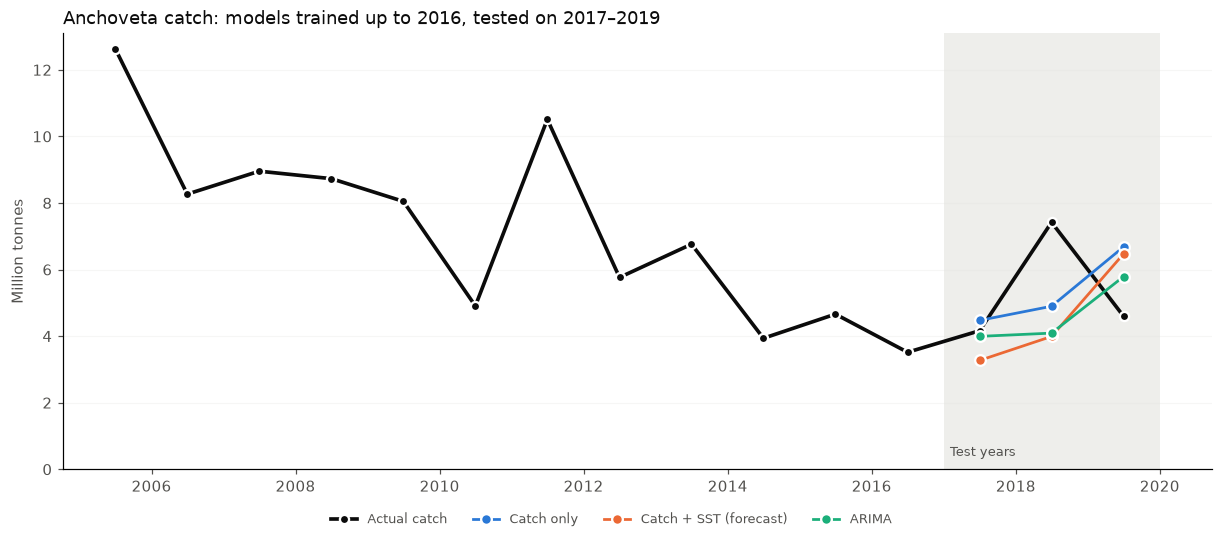

In [16]:
# ============================================================================
# HOLD-OUT TEST: TRAIN ON YEARS UP TO 2016, PREDICT 2017–2019
# Needs the anchoveta model cell above (anch, anch_models, anch_history, ARIMA_CANDIDATES).
#
# Every model is fitted ONCE on the training years and not refitted. Each test year
# is still a one-year-ahead forecast: it uses the previous year's observed catch
# (and SST), as a forecast issued at the start of that year would.
#   Linear models: training years 2005–2016 (where catch and drifter SST overlap)
#   ARIMA: catch history 1982–2016, order chosen by AIC on the training years only
# ============================================================================
TEST_YEARS = [2017, 2018, 2019]
TRAIN_END = TEST_YEARS[0] - 1

ho_train, ho_test = anch.loc[:TRAIN_END], anch.loc[TEST_YEARS]
holdout = pd.DataFrame({"actual": ho_test["log_anch"], "Persistence": ho_test["log_anch_lag1"]})
for name, inputs in anch_models.items():
    fit = sm.OLS(ho_train["log_anch"], sm.add_constant(ho_train[inputs])).fit()
    holdout[name] = fit.predict(sm.add_constant(ho_test[inputs], has_constant="add"))

arima_train = anch_history[anch_history.index.year <= TRAIN_END]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    arima_fits = []
    for order, trend in ARIMA_CANDIDATES:
        try:
            arima_fits.append(ARIMA(arima_train, order=order, trend=trend).fit())
        except (ValueError, np.linalg.LinAlgError):
            continue
    arima_fit = min(arima_fits, key=lambda f: f.aic)
    # One step at a time with the parameters frozen: add each observed year, then forecast the next
    arima_state = arima_fit
    for year in TEST_YEARS:
        holdout.loc[year, "ARIMA"] = arima_state.forecast(1).iloc[0]
        arima_state = arima_state.append(anch_history[anch_history.index.year == year], refit=False)
    # For comparison: a pure 1-, 2- and 3-year-ahead forecast made at the end of 2016
    holdout["ARIMA (from 2016)"] = arima_fit.forecast(len(TEST_YEARS)).to_numpy()

ho_methods = [c for c in holdout.columns if c != "actual"]
ho_err = holdout[ho_methods].sub(holdout["actual"], axis=0)
print(f"Trained on: linear models {ho_train.index.min()}–{TRAIN_END} ({len(ho_train)} years); "
      f"ARIMA{arima_fit.model.order} {arima_train.index.year.min()}–{TRAIN_END} ({len(arima_train)} years)")
print("\nForecasts for the test years (million tonnes)")
print((np.exp(holdout) / 1e6).round(2).T.to_string())
print("\nTest errors over 2017–2019")
print(pd.DataFrame({
    "MAE (log)": ho_err.abs().mean(),
    "Typical error (%)": (np.exp(ho_err.abs().mean()) - 1) * 100,
    "MAE (million t)": (np.exp(holdout[ho_methods]).sub(np.exp(holdout["actual"]), axis=0) / 1e6).abs().mean(),
}).round(3).to_string())

# Figure: the whole catch series, with the training years and the three test-year forecasts
fig, ax = plt.subplots(figsize=(11, 4.8), constrained_layout=True)
hist_years = anch.index
ax.axvspan(pd.Timestamp(f"{TEST_YEARS[0]}-01-01"), pd.Timestamp(f"{TEST_YEARS[-1]}-12-31"), color=GRID, alpha=0.6,
           linewidth=0)
ax.text(pd.Timestamp(f"{TEST_YEARS[0]}-02-01"), 0.4, "Test years", color=MUTED, fontsize=8.5)
ax.plot(pd.to_datetime([f"{y}-07-01" for y in hist_years]), np.exp(anch["log_anch"]) / 1e6, color=INK, lw=2.4,
        marker="o", ms=6, mec="white", mew=1.5, label="Actual catch")
test_x = pd.to_datetime([f"{y}-07-01" for y in TEST_YEARS])
for col, color in [("Catch only", BLUE), ("Catch + SST (forecast)", ORANGE), ("ARIMA", AQUA)]:
    ax.plot(test_x, np.exp(holdout[col]) / 1e6, color=color, lw=1.8, marker="o", ms=7, mec="white", mew=1.5,
            label=col)
ax.set_ylim(bottom=0)
ax.set_ylabel("Million tonnes", color=MUTED)
ax.set_title(f"Anchoveta catch: models trained up to {TRAIN_END}, tested on {TEST_YEARS[0]}–{TEST_YEARS[-1]}",
             loc="left", color=INK)
fig.legend(*ax.get_legend_handles_labels(), frameon=False, loc="outside lower center", ncols=4, fontsize=8.5,
           labelcolor=MUTED)
ax.grid(False, axis="x")
ax.grid(True, axis="y", color=GRID, lw=0.7)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors=MUTED)
fig.savefig("../figures/anchoveta_holdout.png", dpi=200, bbox_inches="tight", pad_inches=0.2)
plt.show()

## Rolling evaluation: which model predicts one year ahead best?

Train on 2002–2014 and predict 2015, then train on 2002–2015 and predict 2016, and so on up to 2019. Compares the best linear model and the best ARIMAX from earlier with ETS, a BSTS on catch alone, and a BSTS with last year's SST, all against persistence. Run the Niño 1+2 cell, the fish-vs-SST cell and the anchoveta model cell above first.

Coastal ENSO state by year (+1 El Niño, 0 neutral, -1 La Niña):
2001:-1 2002:+1 2003:-1 2004:-1 2005:-1 2006:+1 2007:-1 2008:+1 2009:+1 2010:-1 2011:-1 2012:+1 2013:-1 2014:+1 2015:+1 2016:+1 2017:+0 2018:-1 2019:+0



Model details for each forecast year
year                                              2015                          2016                          2017                          2018                          2019
Catch + SST (linear)            11 yrs, SST coef -0.17        12 yrs, SST coef -0.15        13 yrs, SST coef -0.24        14 yrs, SST coef -0.20        15 yrs, SST coef -0.13
ARIMAX (ENSO, same year)       13 yrs, order (1, 1, 0)       14 yrs, order (1, 1, 0)       15 yrs, order (1, 1, 0)       16 yrs, order (1, 1, 0)       17 yrs, order (0, 1, 1)
ETS                                  13 yrs, trend add             14 yrs, trend add             15 yrs, trend add             16 yrs, trend add             17 yrs, trend add
BSTS                                            13 yrs                        14 yrs                        15 yrs                        16 yrs                        17 yrs
BSTS + SST                10 yrs, P(SST included) 0.30  11 yrs, P(SST included) 0.28  1

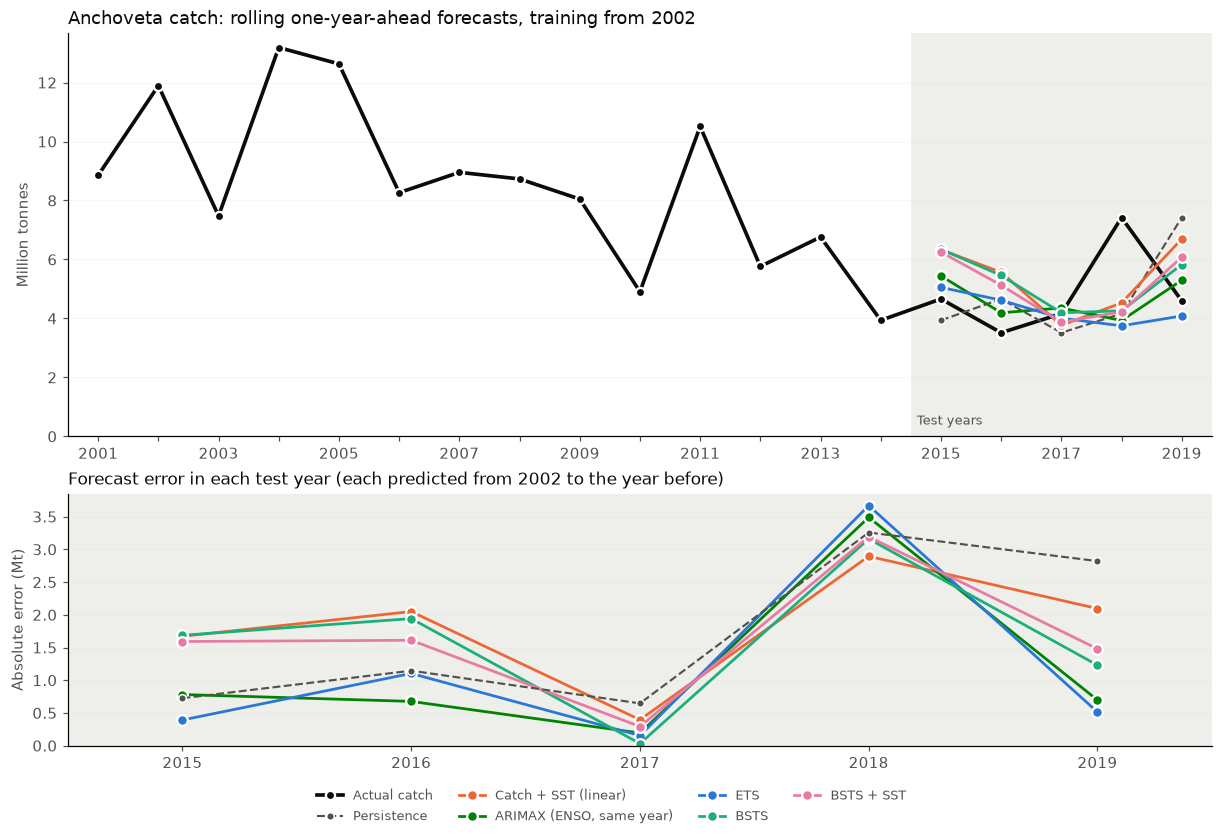

In [17]:
# ============================================================================
# ROLLING ONE-YEAR-AHEAD EVALUATION, TRAINING FROM 2002
# Train on 2002–2014, predict 2015; train on 2002–2015, predict 2016; ... up to 2019.
# Every model is refitted each year on actuals up to the year before only.
# Needs fish_sst (fish-vs-SST cell), coastal_events / nino12_smooth (Niño 1+2 cell) and
# the imports / ARIMA_CANDIDATES from the anchoveta model cell.
#
# Target: log anchoveta catch. Models:
#   persistence          forecast = last year's catch (the reference; no training)
#   Catch + SST          linear: log catch(t) ~ log catch(t-1) + SST(t-1)
#                        (best linear model so far; SST is missing for 2001 and 2003, so
#                        its training years are 2003 and 2005 onward)
#   ARIMAX (ENSO)        ARIMA + the coastal ENSO state of the year being predicted
#                        (+1 El Niño, 0 neutral, -1 La Niña, from Niño 1+2). Best ARIMAX so far,
#                        but a NOWCAST: it needs that year's ENSO state. Niño 1+2 is NOAA's
#                        index, not drifter data.
#   ETS                  exponential smoothing (error-trend-seasonal); the trend form (none,
#                        additive, damped) is chosen by AIC in each window
#   BSTS                 Bayesian structural time series: a local level (random walk) plus
#                        noise, fitted by Gibbs sampling
#   BSTS + SST           the same with last year's SST as a regressor, with a spike-and-slab
#                        prior so the data decide whether SST belongs in the model. Needs an
#                        unbroken SST record, so it trains from 2005.
# ============================================================================
from statsmodels.tsa.exponential_smoothing.ets import ETSModel

ROLL_TRAIN_START = 2002
ROLL_TEST_YEARS = list(range(2015, 2020))
SST_TRAIN_START = 2005       # first year of the unbroken run of sst_lag1
BSTS_DRAWS, BSTS_BURN = 20000, 2000   # fewer draws left the forecast varying by ~1 Mt between seeds

roll = pd.DataFrame({"log_anch": np.log(fish_sst["Anchoveta"]), "sst": fish_sst["sst_anom"]})
roll["log_anch_lag1"] = roll["log_anch"].shift(1)
roll["sst_lag1"] = roll["sst"].shift(1)


# Yearly coastal ENSO state from the Niño 1+2 events (same rule as the `coastal` table)
def event_month_flags(active):
    flags = pd.Series(False, index=nino12_smooth.index)
    for e in coastal_events(active, ""):
        flags.loc[e["start"]:e["end"]] = True
    return flags.groupby(flags.index.year).sum()


warm_months = event_month_flags(nino12_smooth >= COASTAL_WARM)
cold_months = event_month_flags(nino12_smooth <= COASTAL_COLD)
enso_state = pd.Series(np.select(
    [(warm_months >= COASTAL_MIN_MONTHS) & (cold_months < COASTAL_MIN_MONTHS),
     (cold_months >= COASTAL_MIN_MONTHS) & (warm_months < COASTAL_MIN_MONTHS)], [1, -1], 0),
    index=warm_months.index)
roll["enso"] = enso_state.reindex(roll.index)
print("Coastal ENSO state by year (+1 El Niño, 0 neutral, -1 La Niña):")
print(" ".join(f"{y}:{int(v):+d}" for y, v in roll["enso"].items()))


def as_periods(series):
    return series.set_axis(pd.PeriodIndex(series.index.astype(str), freq="Y"))


def best_arima(train, exog=None):
    """Fit every candidate order and keep the lowest AIC (exog makes it an ARIMAX)."""
    fits = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for order, trend in ARIMA_CANDIDATES:
            try:
                fits.append(ARIMA(train, exog=exog, order=order, trend=trend).fit())
            except (ValueError, np.linalg.LinAlgError):
                continue
    return min(fits, key=lambda f: f.aic)


def best_ets(train):
    """ETS with additive errors; no trend, additive trend or damped trend, chosen by AIC."""
    fits = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for trend, damped in [(None, False), ("add", False), ("add", True)]:
            try:
                fits.append(ETSModel(train, error="add", trend=trend, damped_trend=damped).fit(disp=False))
            except (ValueError, np.linalg.LinAlgError):
                continue
    return min(fits, key=lambda f: f.aic)


def bsts_forecast(y, x=None, x_next=None, draws=BSTS_DRAWS, burn=BSTS_BURN, seed=0):
    """Local-level BSTS fitted by Gibbs sampling; optional single regressor with a spike-and-slab prior.

    y_t = mu_t + beta * x_t + e_t,   e_t ~ N(0, s_e^2)
    mu_t = mu_{t-1} + u_t,           u_t ~ N(0, s_u^2)
    Priors follow the R bsts defaults: weak inverse-gamma priors on both variances (guesses sd(y) and
    0.01 sd(y), prior sample size 0.01), level sd capped at sd(y), initial level ~ N(y_1, sd(y)^2).
    beta: included with prior probability 0.5; if included, beta ~ N(0, (sd(y) / sd(x))^2).
    Returns the posterior-median one-step forecast and the posterior inclusion probability of x.
    """
    rng = np.random.default_rng(seed)
    y = np.asarray(y, float); n = len(y); sdy = y.std(ddof=1)
    has_x = x is not None
    x = np.asarray(x, float) if has_x else np.zeros(n)
    tau2 = (sdy / x.std(ddof=1)) ** 2 if has_x else 1.0
    a0, se_b, su_b = 0.005, 0.005 * sdy ** 2, 0.005 * (0.01 * sdy) ** 2   # shape and scale from size 0.01
    se2, su2, beta, gamma = sdy ** 2 / 4, (0.1 * sdy) ** 2, 0.0, 0
    forecasts, included = [], []
    for it in range(draws):
        # 1. Level path by forward filtering, backward sampling
        ys = y - beta * x
        m, P = np.empty(n), np.empty(n)
        m_prev, P_prev = y[0], sdy ** 2
        for t in range(n):
            Pp = P_prev + (su2 if t else 0.0)
            K = Pp / (Pp + se2)
            m[t] = m_prev + K * (ys[t] - m_prev)
            P[t] = (1 - K) * Pp
            m_prev, P_prev = m[t], P[t]
        mu = np.empty(n)
        mu[-1] = rng.normal(m[-1], np.sqrt(P[-1]))
        for t in range(n - 2, -1, -1):
            J = P[t] / (P[t] + su2)
            mu[t] = rng.normal(m[t] + J * (mu[t + 1] - m[t]), np.sqrt((1 - J) * P[t]))
        # 2. Variances
        resid = y - mu - beta * x
        se2 = 1 / rng.gamma(a0 + n / 2, 1 / (se_b + resid @ resid / 2))
        d = np.diff(mu)
        su2 = min(1 / rng.gamma(a0 + (n - 1) / 2, 1 / (su_b + d @ d / 2)), sdy ** 2)
        # 3. Spike-and-slab regression coefficient
        if has_x:
            r = y - mu
            prec = x @ x / se2 + 1 / tau2
            mean = (x @ r / se2) / prec
            log_bf = 0.5 * np.log(1 / (tau2 * prec)) + 0.5 * mean ** 2 * prec
            gamma = int(rng.random() < 1 / (1 + np.exp(-log_bf)))
            beta = rng.normal(mean, np.sqrt(1 / prec)) if gamma else 0.0
        if it >= burn:
            mu_next = mu[-1] + rng.normal(0, np.sqrt(su2))
            forecasts.append(mu_next + (beta * x_next if has_x else 0.0) + rng.normal(0, np.sqrt(se2)))
            included.append(gamma)
    return float(np.median(forecasts)), (float(np.mean(included)) if has_x else np.nan)


roll_rows, roll_notes = [], []
for year in ROLL_TEST_YEARS:
    window = roll.loc[ROLL_TRAIN_START:year - 1]
    test = roll.loc[[year]]
    row = {"year": year, "actual": test["log_anch"].iloc[0], "Persistence": test["log_anch_lag1"].iloc[0]}
    notes = {"year": year}

    # Best linear model: catch + last year's SST
    inputs = ["log_anch_lag1", "sst_lag1"]
    train = window.dropna(subset=["log_anch", *inputs])
    fit = sm.OLS(train["log_anch"], sm.add_constant(train[inputs])).fit()
    row["Catch + SST (linear)"] = fit.predict(sm.add_constant(test[inputs], has_constant="add")).iloc[0]
    notes["Catch + SST (linear)"] = f"{len(train)} yrs, SST coef {fit.params['sst_lag1']:+.2f}"

    # Best ARIMAX: coastal ENSO state of the same year (nowcast)
    enso_fit = best_arima(as_periods(window["log_anch"]), exog=window[["enso"]].to_numpy(float))
    row["ARIMAX (ENSO, same year)"] = enso_fit.forecast(1, exog=test[["enso"]].to_numpy(float)).iloc[0]
    notes["ARIMAX (ENSO, same year)"] = f"{len(window)} yrs, order {enso_fit.model.order}"

    # ETS
    ets = best_ets(as_periods(window["log_anch"]))
    row["ETS"] = ets.forecast(1).iloc[0]
    notes["ETS"] = f"{len(window)} yrs, trend {ets.model.trend or 'none'}{' (damped)' if ets.model.damped_trend else ''}"

    # BSTS on catch alone, and with last year's SST
    row["BSTS"], _ = bsts_forecast(window["log_anch"].to_numpy(), seed=year)
    notes["BSTS"] = f"{len(window)} yrs"
    sst_window = roll.loc[SST_TRAIN_START:year - 1]
    assert sst_window["sst_lag1"].notna().all(), "BSTS + SST needs an unbroken SST record"
    row["BSTS + SST"], p_incl = bsts_forecast(sst_window["log_anch"].to_numpy(), sst_window["sst_lag1"].to_numpy(),
                                              test["sst_lag1"].iloc[0], seed=year)
    notes["BSTS + SST"] = f"{len(sst_window)} yrs, P(SST included) {p_incl:.2f}"

    roll_rows.append(row)
    roll_notes.append(notes)

roll_pred = pd.DataFrame(roll_rows).set_index("year")
roll_methods = [c for c in roll_pred.columns if c != "actual"]
roll_log_err = roll_pred[roll_methods].sub(roll_pred["actual"], axis=0)
roll_t = np.exp(roll_pred) / 1e6
roll_t_err = roll_t[roll_methods].sub(roll_t["actual"], axis=0)

print("\nModel details for each forecast year")
with pd.option_context("display.max_colwidth", 60, "display.width", 250):
    print(pd.DataFrame(roll_notes).set_index("year").T.to_string())
print("\nForecasts (million tonnes)")
print(roll_t.round(2).to_string())

actual_up = np.sign(roll_pred["actual"] - roll_pred["Persistence"])
closest = roll_log_err.drop(columns="Persistence").abs().idxmin(axis=1)
roll_scores = pd.DataFrame({
    "MAE (million t)": roll_t_err.abs().mean(),
    "RMSE (million t)": np.sqrt((roll_t_err ** 2).mean()),
    "Typical error (%)": (np.exp(roll_log_err.abs().mean()) - 1) * 100,
    "Bias (million t)": roll_t_err.mean(),
    "Skill vs persistence": 1 - roll_log_err.abs().mean() / roll_log_err["Persistence"].abs().mean(),
    "Up/down right": [f"{int((np.sign(roll_pred[m] - roll_pred['Persistence']) == actual_up).sum())}/5"
                      if m != "Persistence" else "—" for m in roll_methods],
    "Closest (years)": [int((closest == m).sum()) if m != "Persistence" else "—" for m in roll_methods],
}).sort_values("MAE (million t)")
print(f"\nScores over {ROLL_TEST_YEARS[0]}–{ROLL_TEST_YEARS[-1]} (lower error is better; skill > 0 beats persistence)")
print(roll_scores.round(3).to_string())

# Figure: actual catch with each model's rolling forecasts (top) and the absolute error per year (bottom)
MAGENTA, GREEN = "#e87ba4", "#008300"
roll_lines = [("Catch + SST (linear)", ORANGE), ("ARIMAX (ENSO, same year)", GREEN), ("ETS", BLUE),
              ("BSTS", AQUA), ("BSTS + SST", MAGENTA)]
fig, (ax, ax_err) = plt.subplots(2, 1, figsize=(11, 7.5), constrained_layout=True,
                                 gridspec_kw={"height_ratios": [1.6, 1]})
# Plain integer years on the x-axis, so each point sits exactly on its year's tick
all_x = roll.index.to_numpy()
test_x = np.array(ROLL_TEST_YEARS)
for a in (ax, ax_err):
    a.axvspan(ROLL_TEST_YEARS[0] - 0.5, ROLL_TEST_YEARS[-1] + 0.5, color=GRID, alpha=0.6, linewidth=0)
ax.plot(all_x, np.exp(roll["log_anch"]) / 1e6, color=INK, lw=2.4, marker="o", ms=6, mec="white", mew=1.5,
        label="Actual catch")
ax.plot(test_x, roll_t["Persistence"], color=MUTED, lw=1.4, ls="--", marker="o", ms=5, mec="white", mew=1,
        label="Persistence")
for col, color in roll_lines:
    ax.plot(test_x, roll_t[col], color=color, lw=1.8, marker="o", ms=7, mec="white", mew=1.5, label=col)
    ax_err.plot(test_x, roll_t_err[col].abs(), color=color, lw=1.8, marker="o", ms=7, mec="white", mew=1.5)
ax_err.plot(test_x, roll_t_err["Persistence"].abs(), color=MUTED, lw=1.4, ls="--", marker="o", ms=5,
            mec="white", mew=1)
ax.text(ROLL_TEST_YEARS[0] - 0.4, 0.4, "Test years", color=MUTED, fontsize=8.5)
ax.set_xlim(all_x[0] - 0.5, ROLL_TEST_YEARS[-1] + 0.5)
ax.set_xticks(all_x, [str(y) if y % 2 == 1 else "" for y in all_x])
ax.set_ylim(bottom=0)
ax.set_ylabel("Million tonnes", color=MUTED)
ax.set_title(f"Anchoveta catch: rolling one-year-ahead forecasts, training from {ROLL_TRAIN_START}",
             loc="left", color=INK)
ax_err.set_ylim(bottom=0)
ax_err.set_ylabel("Absolute error (Mt)", color=MUTED)
ax_err.set_title("Forecast error in each test year (each predicted from 2002 to the year before)", loc="left",
                 color=INK, fontsize=11)
ax_err.set_xlim(ROLL_TEST_YEARS[0] - 0.5, ROLL_TEST_YEARS[-1] + 0.5)
ax_err.set_xticks(test_x, [str(y) for y in ROLL_TEST_YEARS])
for a in (ax, ax_err):
    a.grid(False, axis="x")
    a.grid(True, axis="y", color=GRID, lw=0.7)
    a.spines[["top", "right"]].set_visible(False)
    a.tick_params(colors=MUTED)
fig.legend(*ax.get_legend_handles_labels(), frameon=False, loc="outside lower center", ncols=4, fontsize=8.5,
           labelcolor=MUTED)
fig.savefig("../figures/anchoveta_rolling_2015_2019.png", dpi=200, bbox_inches="tight", pad_inches=0.2)
plt.show()